# Importing Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import zscore
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import roc_curve, auc, roc_auc_score
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import label_binarize
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.model_selection import cross_val_score
import lightgbm as lgb
from lightgbm import LGBMClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.tree import plot_tree
from sklearn.model_selection import learning_curve
from sklearn.metrics import log_loss
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.inspection import permutation_importance
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, BatchNormalization, Input
from tensorflow.keras.callbacks import EarlyStopping

C:\Users\aylin\AppData\Local\Programs\Python\Python312\Lib\site-packages\seaborn\_statistics.py:32: UserWarning: A NumPy version >=1.23.5 and <2.3.0 is required for this version of SciPy (detected version 2.3.2)
  from scipy.stats import gaussian_kde


# Loading And Exploring The Dataset 

## Load the dataset

In [2]:
file_path = 'disease_diagnosis.csv'
data = pd.read_csv(file_path)

## Check the shape of the dataset

In [3]:
print(f"Dataset shape: {data.shape}")

Dataset shape: (2000, 13)


-  This dataset contains of 2000 records and 13 fields

## Display the first few rows

In [4]:
data.head()

,Patient_ID,Age,Gender,Symptom_1,Symptom_2,Symptom_3,Heart_Rate_bpm,Body_Temperature_C,Blood_Pressure_mmHg,Oxygen_Saturation_%,Diagnosis,Severity,Treatment_Plan
0,1,74,Male,Fatigue,Sore throat,Fever,69,39.4,132/91,94,Flu,Moderate,Medication and rest
1,2,66,Female,Sore throat,Fatigue,Cough,95,39.0,174/98,98,Healthy,Mild,Rest and fluids
2,3,32,Male,Body ache,Sore throat,Fatigue,77,36.8,136/60,96,Healthy,Mild,Rest and fluids
3,4,21,Female,Shortness of breath,Headache,Cough,72,38.9,147/82,99,Healthy,Mild,Rest and fluids
4,5,53,Male,Runny nose,Sore throat,Fatigue,100,36.6,109/106,92,Healthy,Mild,Rest and fluids


-  **Patient ID:** A unique identifier for each patient.
-  **Patient Information:** Age and gender of the patient.
-  **Symptoms:** Three common symptoms per patient.
-  **Heart Rate (bpm):** Heart rate values in beats per minute.
-  **Body Temperature (Celsius):** Body temperature readings.
-  **Blood Pressure (mmHg):** Systolic and diastolic blood pressure values.
-  **Oxygen Saturation (%):** Oxygen saturation levels in the blood.
-  **Diagnosis:** A rule-based diagnosis generated from symptoms and sensor data, including conditions like Pneumonia, Flu, Bronchitis, Cold, and Healthy.
-  **Severity:** Classification of the condition's severity into Mild, Moderate, and Severe.
-  **Treatment Plan:** Suggested treatment based on the severity of the diagnosis (e.g., rest, medication, or hospitalization).

## Display basic information about the dataset

In [5]:
print(data.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 13 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Patient_ID           2000 non-null   int64  
 1   Age                  2000 non-null   int64  
 2   Gender               2000 non-null   object 
 3   Symptom_1            2000 non-null   object 
 4   Symptom_2            2000 non-null   object 
 5   Symptom_3            2000 non-null   object 
 6   Heart_Rate_bpm       2000 non-null   int64  
 7   Body_Temperature_C   2000 non-null   float64
 8   Blood_Pressure_mmHg  2000 non-null   object 
 9   Oxygen_Saturation_%  2000 non-null   int64  
 10  Diagnosis            2000 non-null   object 
 11  Severity             2000 non-null   object 
 12  Treatment_Plan       2000 non-null   object 
dtypes: float64(1), int64(4), object(8)
memory usage: 203.3+ KB
None


-  The dataset includes both numerical and categorical columns, with data types such as int64 (integer), float64 (floating-point numbers), and object (string or categorical data).
-  Memory usage is approximately 203.3 KB.
-  Patient_ID and Age are recorded as integers (int64), with Patient_ID serving as a unique identifier for each entry.
-  Several columns contain categorical information, such as Gender, Diagnosis, Severity, and Treatment_Plan, as well as symptoms (Symptom_1, Symptom_2, and Symptom_3) and Blood_Pressure_mmHg.
These variables are currently stored as object types.
-  Heart_Rate_bpm, Body_Temperature_C, and Oxygen_Saturation_% are stored as integers or floats and provide essential patient health metrics.

# Data Preprocessing

## Check for missing values


In [6]:
missing_values = data.isnull().sum()
print(missing_values)

Patient_ID             0
Age                    0
Gender                 0
Symptom_1              0
Symptom_2              0
Symptom_3              0
Heart_Rate_bpm         0
Body_Temperature_C     0
Blood_Pressure_mmHg    0
Oxygen_Saturation_%    0
Diagnosis              0
Severity               0
Treatment_Plan         0
dtype: int64


-  There are no missing values

## Check for exact duplicate rows

In [7]:
duplicates = data.duplicated()
print(data[duplicates])

Empty DataFrame
Columns: [Patient_ID, Age, Gender, Symptom_1, Symptom_2, Symptom_3, Heart_Rate_bpm, Body_Temperature_C, Blood_Pressure_mmHg, Oxygen_Saturation_%, Diagnosis, Severity, Treatment_Plan]
Index: []


-  There are no duplicated rows in this dataaset

## Delete the patient's ID

In [8]:
data.pop("Patient_ID")

0          1
1          2
2          3
3          4
4          5
        ... 
1995    1996
1996    1997
1997    1998
1998    1999
1999    2000
Name: Patient_ID, Length: 2000, dtype: int64

## Separate the systolic and diastolic values from the Blood_Pressure_mmHg

In [9]:
# Split the 'Blood_Pressure_mmHg' column into two new columns
data[['Systolic', 'Diastolic']] = data['Blood_Pressure_mmHg'].str.split('/', expand=True)

# Convert the new columns to numeric values (int) for future calculations
data['Systolic'] = pd.to_numeric(data['Systolic'])
data['Diastolic'] = pd.to_numeric(data['Diastolic'])

# Find the index of the 'Blood_Pressure_mmHg' column
col_index = data.columns.get_loc('Blood_Pressure_mmHg')

# Insert the new columns at the same position as the original column
data.insert(col_index + 1, 'Systolic', data.pop('Systolic'))
data.insert(col_index + 2, 'Diastolic', data.pop('Diastolic'))

data.drop(columns=['Blood_Pressure_mmHg'], inplace=True)

# Display the Systolic and Diastolic columns
output = data[['Systolic', 'Diastolic']]
print(output)


      Systolic  Diastolic
0          132         91
1          174         98
2          136         60
3          147         82
4          109        106
...        ...        ...
1995       116        113
1996       166        113
1997        91        103
1998       128         73
1999       127         78

[2000 rows x 2 columns]


## Dispalying the dataset after operating the preprocessing

In [10]:
data.head()

,Age,Gender,Symptom_1,Symptom_2,Symptom_3,Heart_Rate_bpm,Body_Temperature_C,Systolic,Diastolic,Oxygen_Saturation_%,Diagnosis,Severity,Treatment_Plan
0,74,Male,Fatigue,Sore throat,Fever,69,39.4,132,91,94,Flu,Moderate,Medication and rest
1,66,Female,Sore throat,Fatigue,Cough,95,39.0,174,98,98,Healthy,Mild,Rest and fluids
2,32,Male,Body ache,Sore throat,Fatigue,77,36.8,136,60,96,Healthy,Mild,Rest and fluids
3,21,Female,Shortness of breath,Headache,Cough,72,38.9,147,82,99,Healthy,Mild,Rest and fluids
4,53,Male,Runny nose,Sore throat,Fatigue,100,36.6,109,106,92,Healthy,Mild,Rest and fluids


-  The patient_ID has been deleted and the systolic and diastolic values have been separated from the Blood_Pressure_mmHg

# Descriptive Statistics

## Get summary statistics for numerical columns


In [11]:
print(data.describe())

               Age  Heart_Rate_bpm  Body_Temperature_C     Systolic  \
count  2000.000000     2000.000000         2000.000000  2000.000000   
mean     48.285000       89.439000           37.741000   135.731500   
std      17.422616       17.139608            1.309835    25.983879   
min      18.000000       60.000000           35.500000    90.000000   
25%      33.000000       75.000000           36.600000   114.000000   
50%      49.000000       89.000000           37.700000   136.500000   
75%      63.000000      104.000000           38.900000   159.000000   
max      79.000000      119.000000           40.000000   179.000000   

         Diastolic  Oxygen_Saturation_%  
count  2000.000000          2000.000000  
mean     89.338500            94.493500  
std      17.295707             2.861827  
min      60.000000            90.000000  
25%      75.000000            92.000000  
50%      90.000000            95.000000  
75%     104.000000            97.000000  
max     119.000000      

-  **Age:**

The patients’ ages range from 18 to 79 years.<br>
The average age is 48.29 years.<br>
The standard deviation (17.42) indicates moderate variability, meaning there’s a broad age distribution in the dataset.<br>
The 25th percentile (33), 50th percentile (49), and 75th percentile (63) show that 50% of the patients are between 33 and 63 years old, with a median age of 49.<br>

-  **Heart Rate (bpm):**

This represents the heart rate of patients, measured in beats per minute (bpm).<br>
The heart rate ranges from 60 to 119 bpm, with an average heart rate of 89.44 bpm.<br>
A standard deviation of 17.14 bpm indicates a fair amount of variability in heart rate across patients.<br>
The 50th percentile (89 bpm) is close to the mean, indicating that most patients have a similar average heart rate.<br>

-  **Body Temperature (°C):**

This shows the body temperature in Celsius.<br>
The temperature ranges from 35.5°C to 40.0°C, with a mean of 37.74°C, which is slightly above the normal body temperature (around 37°C).<br>
The standard deviation (1.31°C) is small, suggesting that most temperatures are close to the mean.<br>
The 25th percentile (36.6°C), 50th percentile (37.7°C), and 75th percentile (38.9°C) indicate that 50% of patients have a body temperature between 36.6°C and 38.9°C.<br>

-  **Systolic (mmHg):**

This represents the systolic blood pressure of patients, measured in millimeters of mercury (mmHg).<br>
The systolic pressure ranges from 90 mmHg to 179 mmHg, with an average systolic pressure of 135.73 mmHg.<br>
A standard deviation of 25.98 mmHg indicates significant variability in systolic pressure among patients, suggesting that there are various underlying health conditions.<br>
The 25th percentile (114 mmHg), 50th percentile (136.5 mmHg), and 75th percentile (159 mmHg) indicate that 50% of the patients have a systolic pressure between 114 mmHg and 159 mmHg, with a median systolic pressure of 136.5 mmHg.<br>

-  **Diastolic (mmHg):**

This represents the diastolic blood pressure of patients, measured in millimeters of mercury (mmHg).<br>
The diastolic pressure ranges from 60 mmHg to 119 mmHg, with an average diastolic pressure of 89.34 mmHg.<br>
A standard deviation of 17.30 mmHg suggests moderate variability in diastolic pressure across patients, reflecting diverse cardiovascular health.<br>
The 25th percentile (75 mmHg), 50th percentile (90 mmHg), and 75th percentile (104 mmHg) indicate that 50% of the patients have a diastolic pressure between 75 mmHg and 104 mmHg, with a median diastolic pressure of 90 mmHg.<br>

-  **Oxygen Saturation (%):**

This metric measures the percentage of oxygen in the blood.<br>
The values range from 90% to 99%, with a mean of 94.49%.<br>
A standard deviation of 2.86% suggests that most oxygen saturation levels are close to the mean.<br>
The percentiles indicate that 50% of the patients have oxygen saturation between 92% and 97%, with a median of 95%.<br>

## Normalize the numerical columns

In [12]:
# Initialize the scaler
scaler = MinMaxScaler()

# Select the columns you want to normalize
columns_to_normalize = ['Age', 'Heart_Rate_bpm', 'Body_Temperature_C', 'Systolic', 'Diastolic', 'Oxygen_Saturation_%']

# Apply the scaler and create a DataFrame with the normalized values
data[columns_to_normalize] = scaler.fit_transform(data[columns_to_normalize])

# Display the normalized columns
print(data[columns_to_normalize].head())


        Age  Heart_Rate_bpm  Body_Temperature_C  Systolic  Diastolic  \
0  0.918033        0.152542            0.866667  0.471910   0.525424   
1  0.786885        0.593220            0.777778  0.943820   0.644068   
2  0.229508        0.288136            0.288889  0.516854   0.000000   
3  0.049180        0.203390            0.755556  0.640449   0.372881   
4  0.573770        0.677966            0.244444  0.213483   0.779661   

   Oxygen_Saturation_%  
0             0.444444  
1             0.888889  
2             0.666667  
3             1.000000  
4             0.222222  


-  All values in these numerical columns will fall within the range [0, 1], ensuring consistency in feature scaling across the dataset.

## Display summary statistics for categorical columns

In [13]:
for column in ['Gender', 'Diagnosis', 'Severity', 'Treatment_Plan']:
    print("Value counts for", end=' ')
    print(data[column].value_counts())
    print("\n")

Value counts for Gender
Male      1000
Female    1000
Name: count, dtype: int64


Value counts for Diagnosis
Healthy       1167
Bronchitis     334
Flu            292
Cold           163
Pneumonia       44
Name: count, dtype: int64


Value counts for Severity
Mild        1330
Severe       378
Moderate     292
Name: count, dtype: int64


Value counts for Treatment_Plan
Rest and fluids                   1330
Hospitalization and medication     378
Medication and rest                292
Name: count, dtype: int64




-  **Gender:** <br>
There is an equal distribution of Male and Female patients, with each gender having 1000 entries. This balanced distribution reduces any potential gender bias in our analysis.

-  **Diagnosis:** <br>
The dataset includes five different diagnoses with Healthy as the majority of patients and Pneumonia as the least common diagnosis.

-  **Severity:** <br>
The majority of cases are labeled as Mild, while fewer cases are classified as Severe or Moderate

-  **Severity:** <br>
The treatment plan distribution mirrors the severity distribution, indicating that most cases are mild and managed with minimal intervention, while more serious conditions require hospitalization.


## Encoding the categorical columns

#### define mappings


In [14]:
mappings = {
    'Gender': {'Male': 0, 'Female': 1},
    'Diagnosis': {'Healthy': 0, 'Cold': 1, 'Flu': 2, 'Bronchitis': 3, 'Pneumonia': 4},
    'Severity': {'Mild': 0, 'Moderate': 1, 'Severe': 2},
    'Treatment_Plan': {'Rest and fluids': 0, 'Medication and rest': 1, 'Hospitalization and medication': 2}
}

-  **Gender:**<br>
Male: 0<br>
Female: 1<br>

-  **Diagnosis:**<br>
Healthy: 0<br>
Cold: 1<br>
Flu: 2<br>
Bronchitis: 3<br>
Pneumonia: 4<br>

-  **Severity:**<br>
Mild: 0<br>
Moderate: 1<br>
Severe: 2<br>

-  **Treatment Plan:**<br>
Rest and fluids: 0<br>
Medication and rest: 1<br>
Hospitalization and medication: 2<br>

#### encoding function

In [15]:
def encode_columns(data, mappings):
    for column, mapping in mappings.items():
        # Apply the mapping
        data[f'{column}_Encoded'] = data[column].map(mapping)
        # Move the encoded column next to the original column
        cols = list(data.columns)
        index = cols.index(column) + 1  # Get the index to insert the encoded column
        data.insert(index, f'{column}_Encoded', data.pop(f'{column}_Encoded'))
        data.drop(columns=[column], inplace=True)
    
    return data

encode_columns(data, mappings)

,Age,Gender_Encoded,Symptom_1,Symptom_2,Symptom_3,Heart_Rate_bpm,Body_Temperature_C,Systolic,Diastolic,Oxygen_Saturation_%,Diagnosis_Encoded,Severity_Encoded,Treatment_Plan_Encoded
0,0.918033,0,Fatigue,Sore throat,Fever,0.152542,0.866667,0.471910,0.525424,0.444444,2,1,1
1,0.786885,1,Sore throat,Fatigue,Cough,0.593220,0.777778,0.943820,0.644068,0.888889,0,0,0
2,0.229508,0,Body ache,Sore throat,Fatigue,0.288136,0.288889,0.516854,0.000000,0.666667,0,0,0
3,0.049180,1,Shortness of breath,Headache,Cough,0.203390,0.755556,0.640449,0.372881,1.000000,0,0,0
4,0.573770,0,Runny nose,Sore throat,Fatigue,0.677966,0.244444,0.213483,0.779661,0.222222,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1995,0.081967,1,Sore throat,Runny nose,Shortness of breath,0.610169,0.600000,0.292135,0.898305,0.888889,0,0,0
1996,0.934426,0,Fatigue,Cough,Sore throat,0.135593,0.133333,0.853933,0.898305,0.777778,1,0,0
1997,1.000000,0,Fatigue,Runny nose,Fever,0.220339,0.266667,0.011236,0.728814,0.555556,0,0,0
1998,0.622951,1,Cough,Sore throat,Headache,0.118644,0.800000,0.426966,0.220339,0.111111,3,2,2


### Global symptom mapping for the 3 Symptom columns

-  Since the same symptoms appear across multiple columns, all symptoms were encoded consistently across the columns

In [16]:
# Step 1: Identify all unique symptoms across the three symptom columns
symptom_columns = ['Symptom_1', 'Symptom_2', 'Symptom_3']
all_unique_symptoms = pd.unique(data[symptom_columns].values.ravel())

# Step 2: Create a global mapping dictionary for all symptoms
global_symptom_mapping = {symptom: code for code, symptom in enumerate(all_unique_symptoms)}

# Step 3: Replace each symptom column with its encoded values using the global mapping
for column in symptom_columns:
    data[column] = data[column].map(global_symptom_mapping)

# Display the modified DataFrame and the mapping
print(data[symptom_columns].head())

   Symptom_1  Symptom_2  Symptom_3
0          0          1          2
1          1          0          3
2          4          1          0
3          5          6          3
4          7          1          0


In [17]:
# Display the symptoms mapping
print("\n\033[1m• Symptoms: \033[0m")  # \033[1m for bold, \033[0m to reset
for symptom, code in global_symptom_mapping.items():
    print(f"  {symptom} : {code}")


• Symptoms: 
  Fatigue : 0
  Sore throat : 1
  Fever : 2
  Cough : 3
  Body ache : 4
  Shortness of breath : 5
  Headache : 6
  Runny nose : 7


-  Categorical variables (Gender, Diagnosis, Severity, Treatment Plan, and Symptoms) have been replaced by encoded versions , representing each category as an integer.

## Convert encoded columns to categorical

In [18]:
# List of columns to convert to categorical
encoded_columns = ['Gender_Encoded', 'Diagnosis_Encoded', 'Severity_Encoded', 'Treatment_Plan_Encoded']

# Convert the encoded columns to categorical
for column in encoded_columns:
    data[column] = data[column].astype('category')

for column in symptom_columns:
    data[column] = data[column].astype('category')

# Display the DataFrame to confirm changes
print(data.dtypes)

Age                        float64
Gender_Encoded            category
Symptom_1                 category
Symptom_2                 category
Symptom_3                 category
Heart_Rate_bpm             float64
Body_Temperature_C         float64
Systolic                   float64
Diastolic                  float64
Oxygen_Saturation_%        float64
Diagnosis_Encoded         category
Severity_Encoded          category
Treatment_Plan_Encoded    category
dtype: object


-  Seven columns are now categorized as category types (Gender_Encoded, Diagnosis_Encoded, Severity_Encoded, Treatment_Plan_Encoded, and 3 Symptoms), reducing memory usage and improving model performance.

## Display the dataset after normalization and encoding 

In [19]:
data.head()

,Age,Gender_Encoded,Symptom_1,Symptom_2,Symptom_3,Heart_Rate_bpm,Body_Temperature_C,Systolic,Diastolic,Oxygen_Saturation_%,Diagnosis_Encoded,Severity_Encoded,Treatment_Plan_Encoded
0,0.918033,0,0,1,2,0.152542,0.866667,0.471910,0.525424,0.444444,2,1,1
1,0.786885,1,1,0,3,0.593220,0.777778,0.943820,0.644068,0.888889,0,0,0
2,0.229508,0,4,1,0,0.288136,0.288889,0.516854,0.000000,0.666667,0,0,0
3,0.049180,1,5,6,3,0.203390,0.755556,0.640449,0.372881,1.000000,0,0,0
4,0.573770,0,7,1,0,0.677966,0.244444,0.213483,0.779661,0.222222,0,0,0


In [20]:
print(data.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 13 columns):
 #   Column                  Non-Null Count  Dtype   
---  ------                  --------------  -----   
 0   Age                     2000 non-null   float64 
 1   Gender_Encoded          2000 non-null   category
 2   Symptom_1               2000 non-null   category
 3   Symptom_2               2000 non-null   category
 4   Symptom_3               2000 non-null   category
 5   Heart_Rate_bpm          2000 non-null   float64 
 6   Body_Temperature_C      2000 non-null   float64 
 7   Systolic                2000 non-null   float64 
 8   Diastolic               2000 non-null   float64 
 9   Oxygen_Saturation_%     2000 non-null   float64 
 10  Diagnosis_Encoded       2000 non-null   category
 11  Severity_Encoded        2000 non-null   category
 12  Treatment_Plan_Encoded  2000 non-null   category
dtypes: category(7), float64(6)
memory usage: 109.2 KB
None


-  The dataset now includes 13 columns with optimized data types only as category and float64. This processed dataset is now well-structured and optimized for training machine learning models, with clear distinctions between categorical and numerical data and reduced memory usage.

# Checking Outliers

## Outlier Analysis Using Boxplot, Scatter Plot, and Histogram

Age
median:  0.5081967213114754
mean:  0.49647540983606564
std_dev:  0.2856166559686706


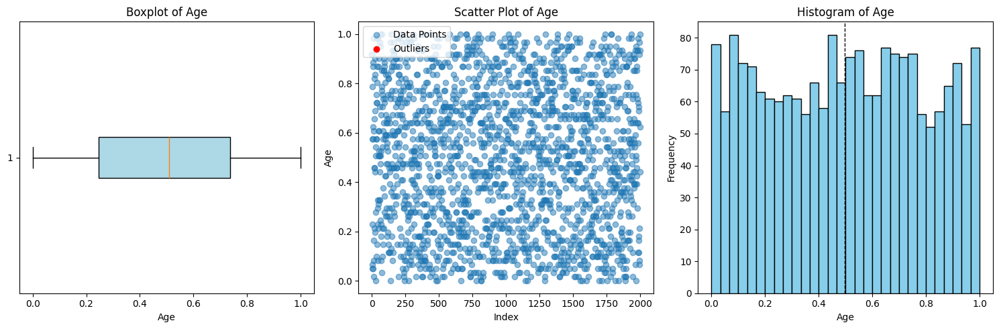

Heart_Rate_bpm
median:  0.4915254237288136
mean:  0.49896610169491534
std_dev:  0.29050183035389976


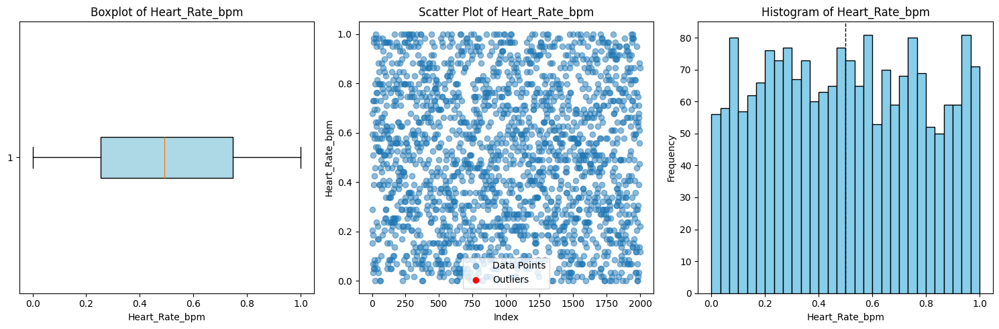

Body_Temperature_C
median:  0.4888888888888898
mean:  0.4980000000000001
std_dev:  0.2910743686241729


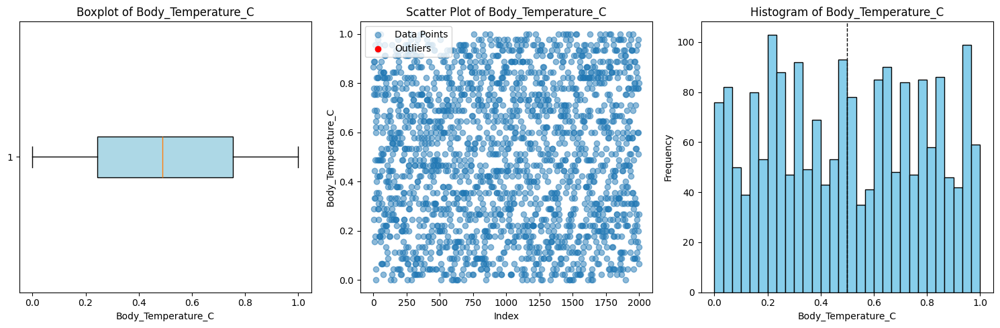

Systolic
median:  0.5224719101123595
mean:  0.5138370786516853
std_dev:  0.29195370113886593


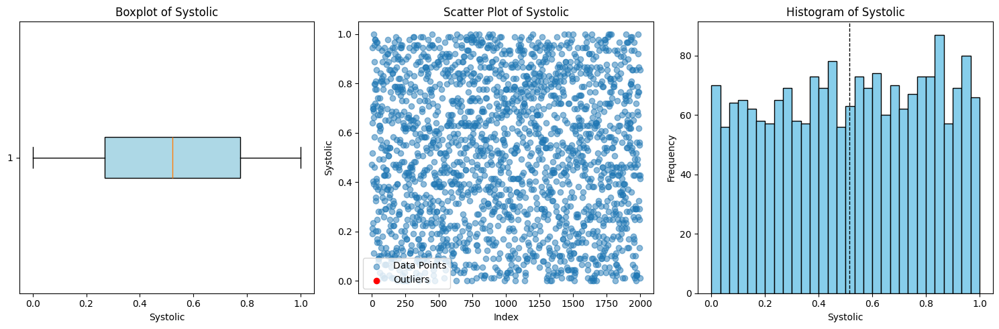

Diastolic
median:  0.5084745762711864
mean:  0.4972627118644068
std_dev:  0.29314758012459596


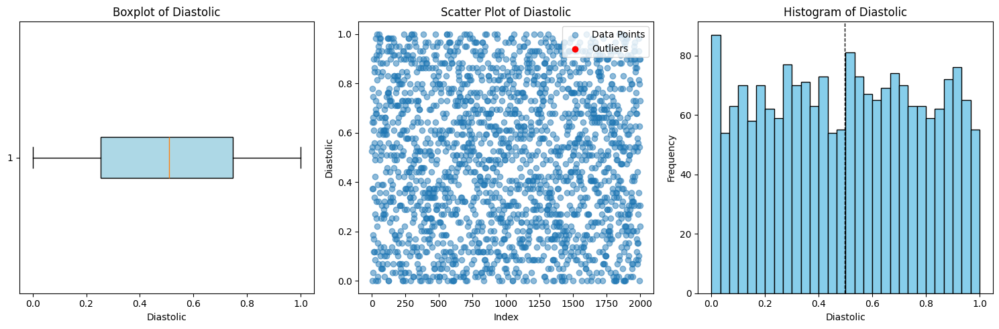

Oxygen_Saturation_%
median:  0.5555555555555554
mean:  0.4992777777777772
std_dev:  0.3179807583352475


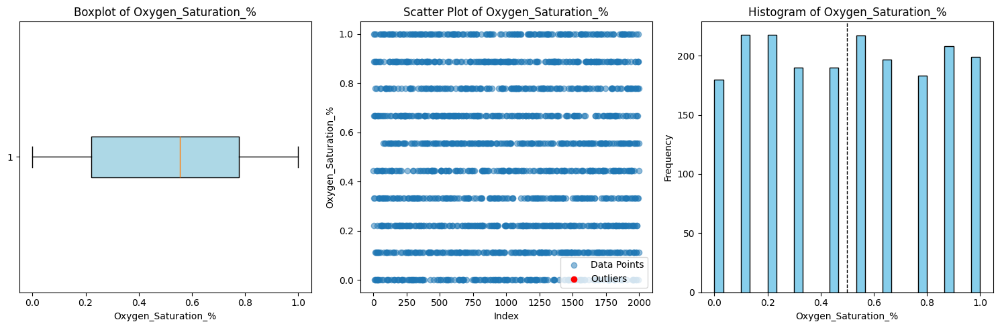

In [21]:
# List of columns you want to check for outliers
columns_to_check = ['Age', 'Heart_Rate_bpm', 'Body_Temperature_C', 'Systolic', 'Diastolic', 'Oxygen_Saturation_%']

# Loop through each column and generate plots for each column's outliers
for column in columns_to_check:
    mean = data[column].mean()
    std_dev = data[column].std()
    median = data[column].median()

    print(column)
    print("median: ", median)
    print("mean: ", mean)
    print("std_dev: ", std_dev)
    
    # Define outliers
    outliers = data[(data[column] > mean + 2 * std_dev) | (data[column] < mean - 2 * std_dev)]

    # Create subplots with 1 row and 3 columns
    fig, axs = plt.subplots(1, 3, figsize=(15, 5))

    # Step 2.1: Boxplot
    axs[0].boxplot(data[column], vert=False, patch_artist=True, boxprops=dict(facecolor="lightblue"))
    axs[0].set_title(f'Boxplot of {column}')
    axs[0].set_xlabel(column)

    # Step 2.2: Scatter Plot
    axs[1].scatter(data.index, data[column], alpha=0.5, label='Data Points')
    axs[1].scatter(outliers.index, outliers[column], color='red', label='Outliers')
    axs[1].set_title(f'Scatter Plot of {column}')
    axs[1].set_xlabel('Index')
    axs[1].set_ylabel(column)
    axs[1].legend()

    # Step 2.3: Histogram
    axs[2].hist(data[column], bins=30, color='skyblue', edgecolor='black')
    axs[2].axvline(mean, color='k', linestyle='dashed', linewidth=1 , label='Mean')
    axs[2].set_title(f'Histogram of {column}')
    axs[2].set_xlabel(column)
    axs[2].set_ylabel('Frequency')

    # Adjust layout to prevent overlapping
    plt.tight_layout()
    plt.show()

#### **Age**
**Boxplot**:
   - The boxplot provides a summary of the distribution of the variable.
   - **Median (0.508)**: The central line in the box represents the median, showing that half of the data points have an age below this value.
   - **Interquartile Range (IQR)**: The box itself captures the middle 50% of the data, indicating that the majority of the `Age` values are tightly clustered.
   - **Whiskers**: The lines extending from the box represent the range of the data excluding outliers. Since there are no outliers, the whiskers span the entire range.
   - **No Outliers Detected**: There are no dots outside the whiskers, indicating that all values are within the expected range.

**Scatter Plot**:
   - This plot shows each individual data point across the dataset.
   - **Uniform Distribution**: The points are evenly spread along the index, indicating no particular pattern or concentration of outliers.
   - **No Red Dots (Outliers)**: As there are no red dots, it confirms that no outliers were detected in the `Age` data.

**Histogram**:
   - The histogram shows the frequency distribution`.
   - **Mean (0.496)**: The dashed line indicates the mean, which is very close to the median, suggesting a fairly symmetrical distribution.
   - **Well-Distributed Data**: The histogram bars indicate that `Age` values are fairly evenly spread, with no significant skewness or extreme values.

---
#### **Heart_Rate_bpm**
**Boxplot**:
- **Median (0.492)**: The middle line of the box, indicating the central tendency of the heart rate.
- **Tightly Packed IQR**: The interquartile range suggests most of the heart rate data is concentrated around the median.
- **No Outliers Detected**: The absence of dots outside the whiskers confirms there are no outliers.

**Scatter Plot**:
- **Even Distribution**: The values are uniformly distributed along the index.
- **No Red Dots (Outliers)**: Consistent with the boxplot, there are no red dots, indicating the absence of outliers.

**Histogram**:
- **Mean (0.499)**: The dashed line near the center aligns closely with the median, reinforcing the symmetrical nature of the distribution.
- **No Significant Skew**: The histogram is relatively balanced, with no long tails, which further supports the conclusion of a lack of outliers.

---

#### **Body_Temperature_C**

**Boxplot**:
- **Median (0.489)**: The central line in the boxplot indicates the median body temperature, showing the middle value of the dataset.
- **Mean (0.498)**: The mean is close to the median, suggesting a symmetric distribution of body temperature values.
- **IQR**: The box represents the interquartile range (middle 50% of the data). The whiskers extend to the most extreme data points not considered outliers.
- **No Outliers**: There are no points outside the whiskers, indicating no outliers in body temperature data.

**Scatter Plot**:
- **Uniform Spread**: The points are evenly distributed without any concentration, confirming no unusual data patterns.
- **No Red Dots**: Consistent with the boxplot, no outliers are detected.

**Histogram**:
- **Symmetric Distribution**: The distribution appears balanced around the mean (dashed line), with no skewness.
- **No Extreme Values**: The histogram bars are evenly spread, indicating a well-distributed dataset with no extreme or unusual values.

---

#### **Systolic**

**Boxplot**:
- **Median (0.522)**: The median systolic value is slightly above the mean, indicating a slight right skew.
- **Mean (0.514)**: The mean is close to the median, showing a nearly symmetric distribution with a slight skew.
- **IQR**: The boxplot shows a compact interquartile range, indicating that most of the data is concentrated around the median.
- **No Outliers**: The absence of outliers is confirmed as there are no points outside the whiskers.

**Scatter Plot**:
- **Even Spread**: The points are distributed uniformly across the index.
- **No Red Dots**: Consistent with the boxplot, the scatter plot does not show any outliers.

**Histogram**:
- **Slight Skewness**: There is a minor skew to the right, as indicated by the slightly higher median than the mean.
- **Balanced Distribution**: Despite the minor skew, the data is well spread, with no significant deviations or clusters of values.

---

#### **Diastolic**

**Boxplot**:
- **Median (0.508)**: The central line in the box represents the median diastolic value.
- **Mean (0.497)**: The mean is close to the median, indicating a symmetric distribution.
- **IQR**: The interquartile range is well-defined, showing that the middle 50% of data is tightly packed around the median.
- **No Outliers**: The whiskers extend without any points outside, suggesting no significant outliers in the diastolic data.

**Scatter Plot**:
- **Uniform Spread**: The points are evenly distributed, confirming a consistent data pattern with no visible outliers (as no red dots are present).

**Histogram**:
- **Symmetric Distribution**: The histogram bars show a fairly even spread around the mean (indicated by the dashed line), with no noticeable skewness or clustering of values.

---

#### **Oxygen_Saturation_%**

**Boxplot**:
- **Median (0.556)**: The median is slightly above the mean, which may suggest a minor skew.
- **Mean (0.499)**: The mean is slightly lower than the median, indicating a slight left skew.
- **IQR**: The interquartile range is compact, and the data is concentrated around the median.
- **No Outliers**: The absence of points outside the whiskers confirms no significant outliers.

**Scatter Plot**:
- **Distinct Lines**: The horizontal bands suggest that the values are concentrated at specific levels, likely due to rounding or categorical measurements.
- **No Outliers**: Similar to the boxplot, no red dots (outliers) are visible.

**Histogram**:
- **Clustered Distribution**: The bars reflect distinct peaks, aligning with the layered pattern observed in the scatter plot.
- **Slight Skew**: The distribution has a minor skew to the left, as the mean is lower than the median.

## Calculating Z-scores

In [22]:
# Calculate Z-scores
z_scores = data[columns_to_check].apply(zscore)

# Identify outliers (absolute Z-score > 2)
outliers = (z_scores > 2) | (z_scores < -2)

# Display number of outliers in each column
outlier_counts = outliers.sum()
print(outlier_counts)


Age                    0
Heart_Rate_bpm         0
Body_Temperature_C     0
Systolic               0
Diastolic              0
Oxygen_Saturation_%    0
dtype: int64


-  The result shows that there are no outliers in any of the columns
-  This implies that all data points fall within 2 standard deviations of the mean, indicating a well-behaved dataset with no extreme values.

# Correlation


Correlations with Diagnosis_Encoded:

Diagnosis_Encoded         1.000000
Severity_Encoded          0.965567
Treatment_Plan_Encoded    0.965567
Body_Temperature_C        0.154860
Heart_Rate_bpm            0.015182
Systolic                  0.001675
Age                      -0.008631
Diastolic                -0.016985
Gender_Encoded           -0.025741
Symptom_3                -0.032800
Symptom_1                -0.040365
Symptom_2                -0.069890
Oxygen_Saturation_%      -0.313920
Name: Diagnosis_Encoded, dtype: float64

Correlations with Severity_Encoded:

Severity_Encoded          1.000000
Treatment_Plan_Encoded    1.000000
Diagnosis_Encoded         0.965567
Body_Temperature_C        0.177936
Heart_Rate_bpm            0.006960
Systolic                  0.005744
Age                      -0.010172
Diastolic                -0.015907
Gender_Encoded           -0.021462
Symptom_3                -0.022991
Symptom_1                -0.028694
Symptom_2                -0.063113
Oxygen_S

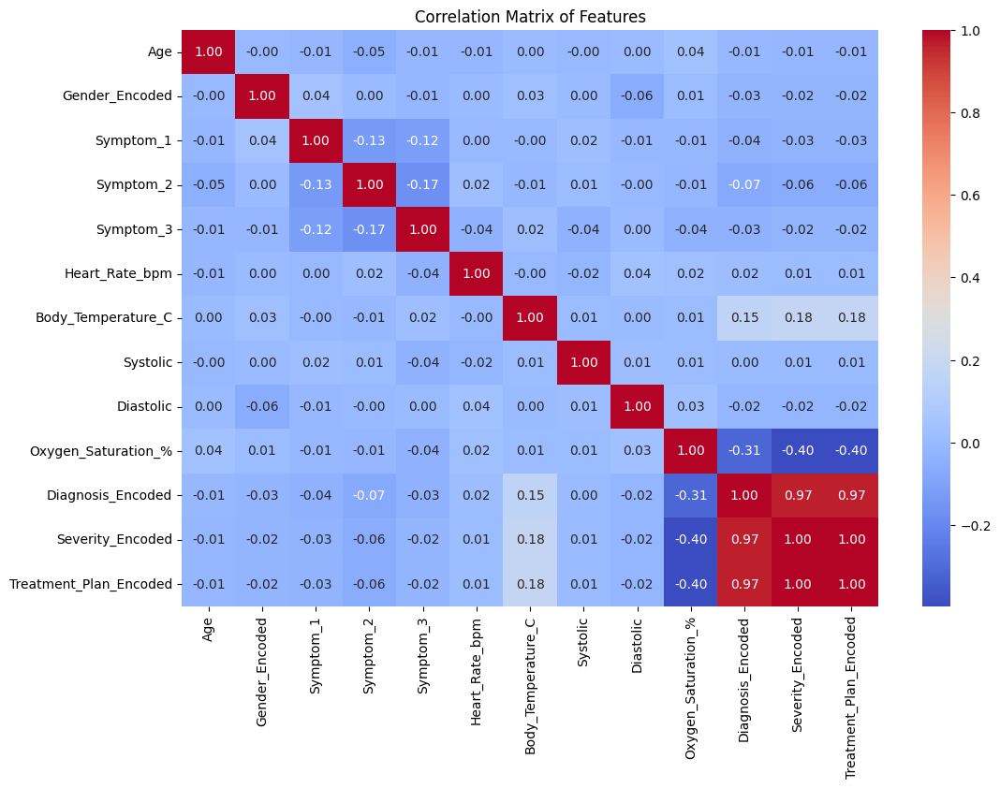

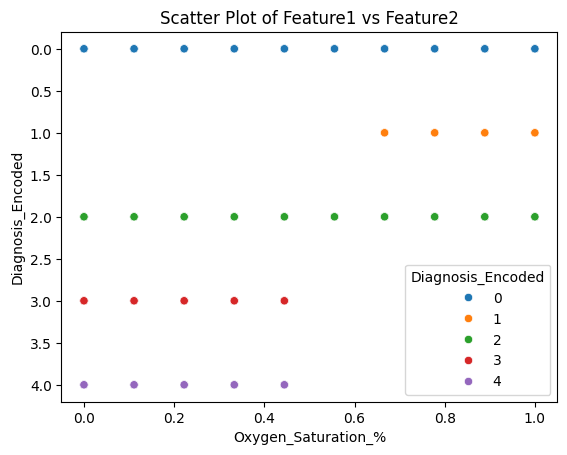

In [26]:
# 1. Compute correlation matrix
correlation_matrix = data.corr()

# 2. Plot heatmap
plt.figure(figsize=(12, 8))
sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Matrix of Features")

# 3. Focused correlations with target variables
targets = ['Diagnosis_Encoded', 'Severity_Encoded', 'Treatment_Plan_Encoded']  # Replace with your actual target column names
for target in targets:
    if target in correlation_matrix:
        correlations = correlation_matrix[target].sort_values(ascending=False)
        print(f"\nCorrelations with {target}:\n")
        print(correlations)


# Save as high-DPI image (300 dpi)
plt.savefig("correlation_matrix.png", dpi=600, bbox_inches='tight')  # PNG
# You can also save as TIFF for IEEE: 
plt.savefig("correlation_matrix.tiff", dpi=600, bbox_inches='tight')

plt.show()
# 4. Explore relationships for top correlations
# Replace 'Feature1' and 'Feature2' with features that show high correlation in the heatmap
sns.scatterplot(data=data, x='Oxygen_Saturation_%', y='Diagnosis_Encoded', hue='Diagnosis_Encoded')
plt.title("Scatter Plot of Feature1 vs Feature2")
plt.show()



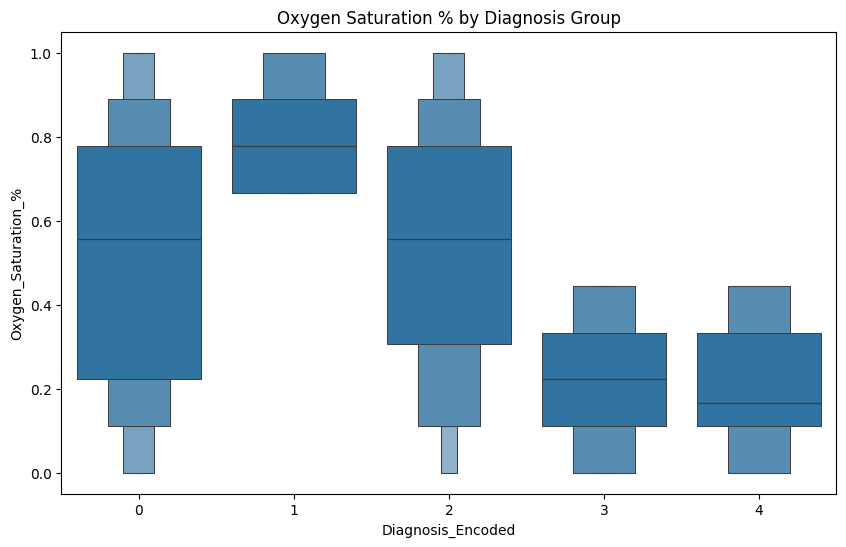

In [24]:
plt.figure(figsize=(10, 6))
sns.boxenplot(data=data, x='Diagnosis_Encoded', y='Oxygen_Saturation_%')
plt.title("Oxygen Saturation % by Diagnosis Group")
plt.show()

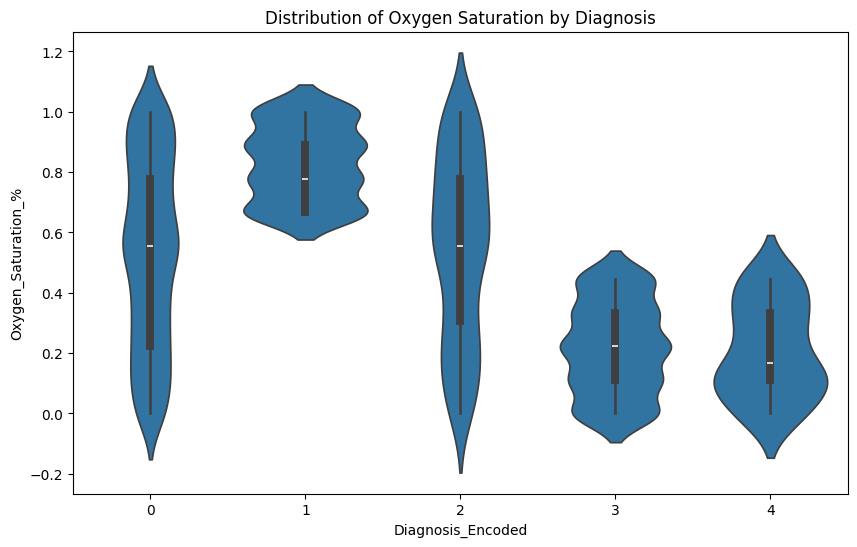

In [25]:
plt.figure(figsize=(10, 6))
sns.violinplot(data=data, x='Diagnosis_Encoded', y='Oxygen_Saturation_%')
plt.title("Distribution of Oxygen Saturation by Diagnosis")
plt.show()

# Models

In [26]:
# Defining Features (X) and Target (y)
X = data.drop(columns=['Diagnosis_Encoded', 'Severity_Encoded', 'Treatment_Plan_Encoded'])  # Drop target and unrelated columns
y = data['Diagnosis_Encoded']  # Target column

In [28]:
# --- Confusion Matrix & Classification Report Plot ---
def plot_model_performance(y_true, y_pred, model_name="Model"):
    # Generate confusion matrix
    cm = confusion_matrix(y_true, y_pred)
    report = classification_report(y_true, y_pred, output_dict=True)
    
    # Create figure with 2 subplots
    fig, ax = plt.subplots(1, 2, figsize=(12, 5))

    # Left: Confusion Matrix (heatmap)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax[0])
    ax[0].set_title(f"Confusion Matrix - {model_name}", pad=20)
    ax[0].set_xlabel("Predicted Lable")
    ax[0].set_ylabel("Actual Lable")

    # Right: Classification Report (as table)
    ax[1].axis('off')  # Remove axes
    report_text = classification_report(y_true, y_pred)
    ax[1].text(0.01, 0.25, str(report_text), fontsize=10, fontfamily='monospace')
    ax[1].set_title(f"Classification Report - {model_name}", pad=20)

    plt.tight_layout()
    plt.show()


# Logistic Regression:

## Basic:

In [87]:
# Step 1: Data Preparation
X_train_lr, X_test_lr, y_train_lr, y_test_lr = train_test_split(X, y, test_size=0.2, random_state=42)

# Step 2: Model Initialization
lr_model = LogisticRegression(random_state=42)

# Step 3: Training
lr_model.fit(X_train_lr, y_train_lr)

# Step 4: Evaluation
lr_y_pred = lr_model.predict(X_test_lr)
lr_y_pred_proba = lr_model.predict_proba(X_test_lr)

#Step 5: Display
print(f"Accuracy for Logistic Regression: {accuracy_score(y_test_lr, lr_y_pred):.2f}","\n")

print("Classification Report for Logistic Regression:")
print(classification_report(y_test_lr, lr_y_pred),"\n")

print("Confusion Matrix for Logistic Regression:")
print(confusion_matrix(y_test_lr, lr_y_pred))

Accuracy for Logistic Regression: 0.64 

Classification Report for Logistic Regression:
              precision    recall  f1-score   support

           0       0.66      0.88      0.76       238
           1       0.94      0.59      0.72        29
           2       0.45      0.26      0.33        58
           3       0.34      0.17      0.23        64
           4       1.00      0.09      0.17        11

    accuracy                           0.64       400
   macro avg       0.68      0.40      0.44       400
weighted avg       0.61      0.64      0.59       400
 

Confusion Matrix for Logistic Regression:
[[210   1  10  17   0]
 [ 12  17   0   0   0]
 [ 40   0  15   3   0]
 [ 46   0   7  11   0]
 [  8   0   1   1   1]]


C:\Users\aylin\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\linear_model\_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


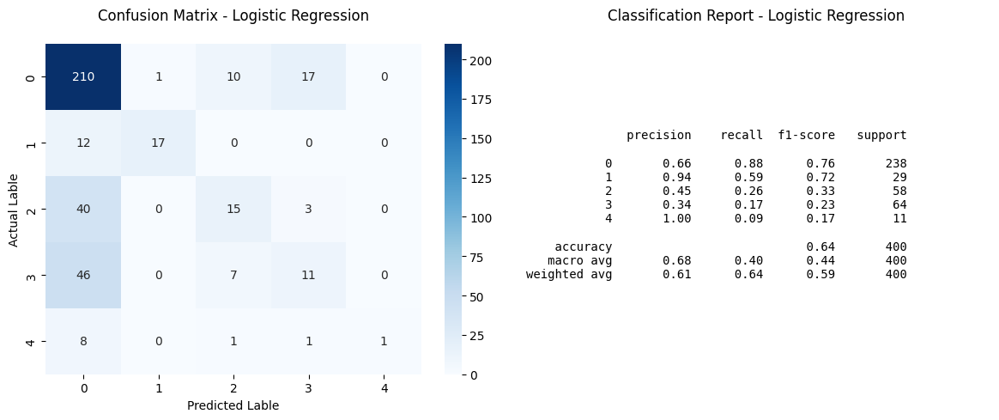

In [30]:
plot_model_performance(y_test_lr, lr_y_pred, model_name="Logistic Regression")

## feature importance:

Feature Importance:
               Feature  Importance
6   Body_Temperature_C    0.097167
9  Oxygen_Saturation_%    0.074917
3            Symptom_2    0.019750
4            Symptom_3    0.014000
5       Heart_Rate_bpm    0.007333
1       Gender_Encoded    0.005083
2            Symptom_1   -0.003333
8            Diastolic   -0.003500
0                  Age   -0.006250
7             Systolic   -0.008917


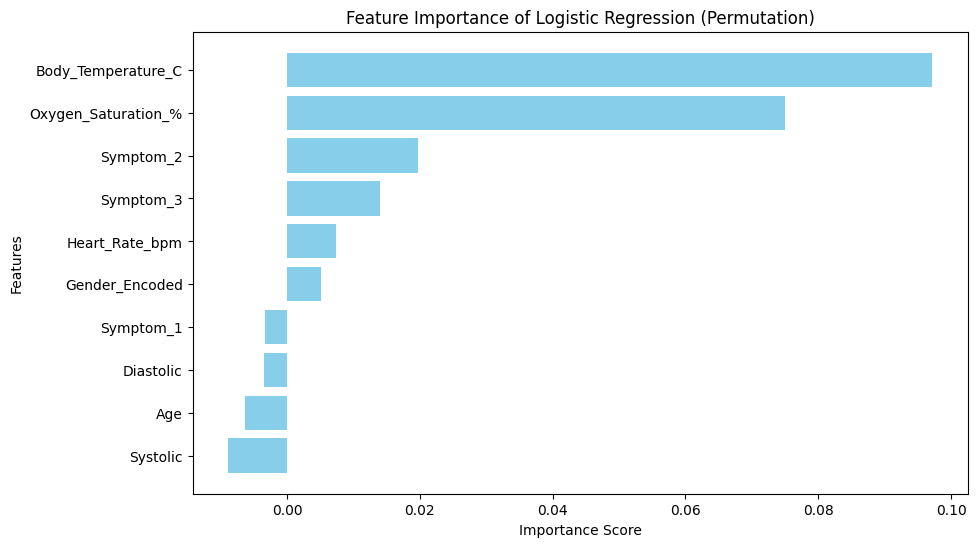

In [99]:
# For non-linear SVM, use permutation importance
result = permutation_importance(lr_model, X_test_lr, y_test_lr, n_repeats=30, random_state=42)

# Create a DataFrame for feature importance
feature_importances = pd.DataFrame({
    'Feature': X.columns,
    'Importance': result.importances_mean
}).sort_values(by='Importance', ascending=False)

# Display the feature importance
print("Feature Importance:")
print(feature_importances)

# Step 7: Plot the feature importances
plt.figure(figsize=(10, 6))
plt.barh(feature_importances['Feature'], feature_importances['Importance'], color='skyblue')
plt.gca().invert_yaxis()  
plt.title('Feature Importance of Logistic Regression (Permutation)')
plt.xlabel('Importance Score')
plt.ylabel('Features')
plt.show()

## Grid Search

In [100]:
# Step 2: Model Initialization and Grid Search Setup

# Define Hyperparameters for Grid Search
#lr_param_grid =  {
#    'C': [0.1, 1, 10, 1000, 20000],
#    'solver': ['liblinear', 'lbfgs', 'saga'], 
#    'max_iter': [100, 150, 200, 500, 1000], 
#    'penalty': ['l1','l2']  
#}
lr_param_grid = {'C': [20000], 'max_iter': [150], 'penalty': ['l2'], 'solver': ['lbfgs']} 

# Define Logistic Regression Model
lr_model = LogisticRegression(random_state=42)

# Initialize GridSearchCV
lr_grid_search = GridSearchCV(
    lr_model,
    lr_param_grid, 
    cv=5, 
    scoring='accuracy', 
    verbose=2, 
    n_jobs=-1
)

# Step 3: Training
lr_grid_search.fit(X_train_lr, y_train_lr)

# Step 4: Evaluation
best_lr_model = lr_grid_search.best_estimator_
y_pred_lr = best_lr_model.predict(X_test_lr)
y_pred_lr_proba = best_lr_model.predict_proba(X_test_lr)

# Step 5: Display
print(f"Accuracy for Logistic Regression: {accuracy_score(y_test_lr, y_pred_lr):.2f}","\n")

print("Best Parameters for Logistic Regression:")
print(lr_grid_search.best_params_,"\n")

print("Classification Report for Logistic Regression:")
print(classification_report(y_test_lr, y_pred_lr),"\n")

print("Confusion Matrix for Logistic Regression:")
print(confusion_matrix(y_test_lr, y_pred_lr))

Fitting 5 folds for each of 1 candidates, totalling 5 fits
Accuracy for Logistic Regression: 0.64 

Best Parameters for Logistic Regression:
{'C': 20000, 'max_iter': 150, 'penalty': 'l2', 'solver': 'lbfgs'} 

Classification Report for Logistic Regression:
              precision    recall  f1-score   support

           0       0.69      0.84      0.76       238
           1       0.82      0.79      0.81        29
           2       0.42      0.29      0.35        58
           3       0.37      0.20      0.26        64
           4       0.60      0.27      0.38        11

    accuracy                           0.64       400
   macro avg       0.58      0.48      0.51       400
weighted avg       0.61      0.64      0.61       400
 

Confusion Matrix for Logistic Regression:
[[201   5  13  18   1]
 [  6  23   0   0   0]
 [ 38   0  17   3   0]
 [ 41   0   9  13   1]
 [  6   0   1   1   3]]


C:\Users\aylin\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\linear_model\_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


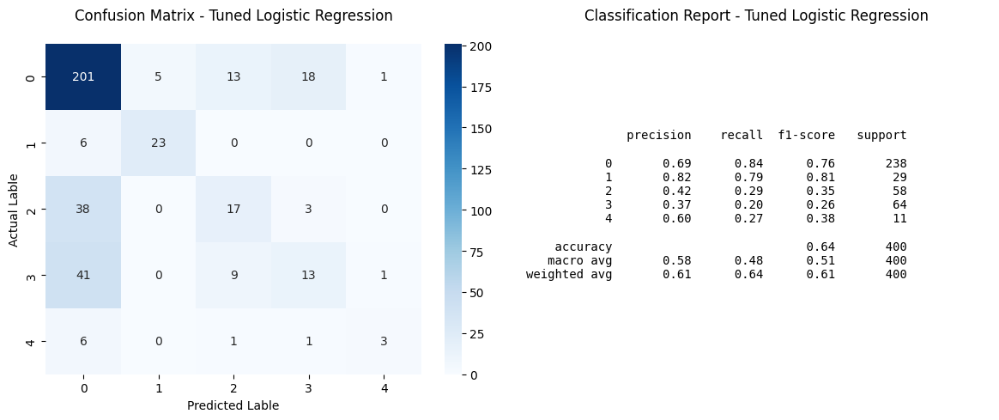

In [101]:
plot_model_performance(y_test_lr, y_pred_lr, model_name="Tuned Logistic Regression")

## Feature importance

Feature Importance:
               Feature  Importance
6   Body_Temperature_C    0.123667
9  Oxygen_Saturation_%    0.101000
3            Symptom_2    0.016250
5       Heart_Rate_bpm    0.014667
4            Symptom_3    0.013417
2            Symptom_1    0.003000
1       Gender_Encoded   -0.001250
7             Systolic   -0.002750
0                  Age   -0.003833
8            Diastolic   -0.004417


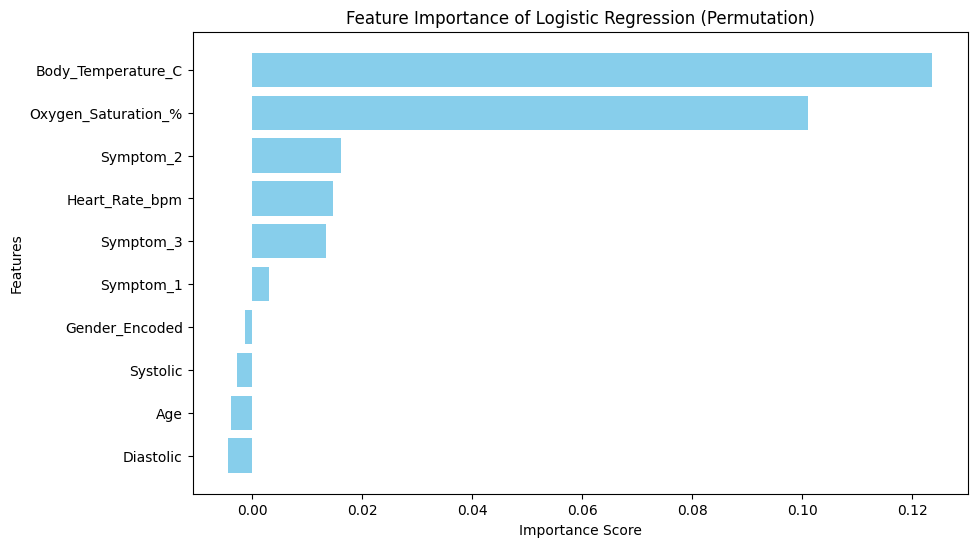

In [103]:
# For non-linear SVM, use permutation importance
result = permutation_importance(best_lr_model, X_test_lr, y_test_lr, n_repeats=30, random_state=42)

# Create a DataFrame for feature importance
feature_importances = pd.DataFrame({
    'Feature': X.columns,
    'Importance': result.importances_mean
}).sort_values(by='Importance', ascending=False)

# Display the feature importance
print("Feature Importance:")
print(feature_importances)

# Step 7: Plot the feature importances
plt.figure(figsize=(10, 6))
plt.barh(feature_importances['Feature'], feature_importances['Importance'], color='skyblue')
plt.gca().invert_yaxis()  
plt.title('Feature Importance of Logistic Regression (Permutation)')
plt.xlabel('Importance Score')
plt.ylabel('Features')
plt.show()

## Plot ROC Curves For Each Class

Class 0: AUC = 0.7580
Class 1: AUC = 0.9933
Class 2: AUC = 0.8537
Class 3: AUC = 0.7832
Class 4: AUC = 0.9689


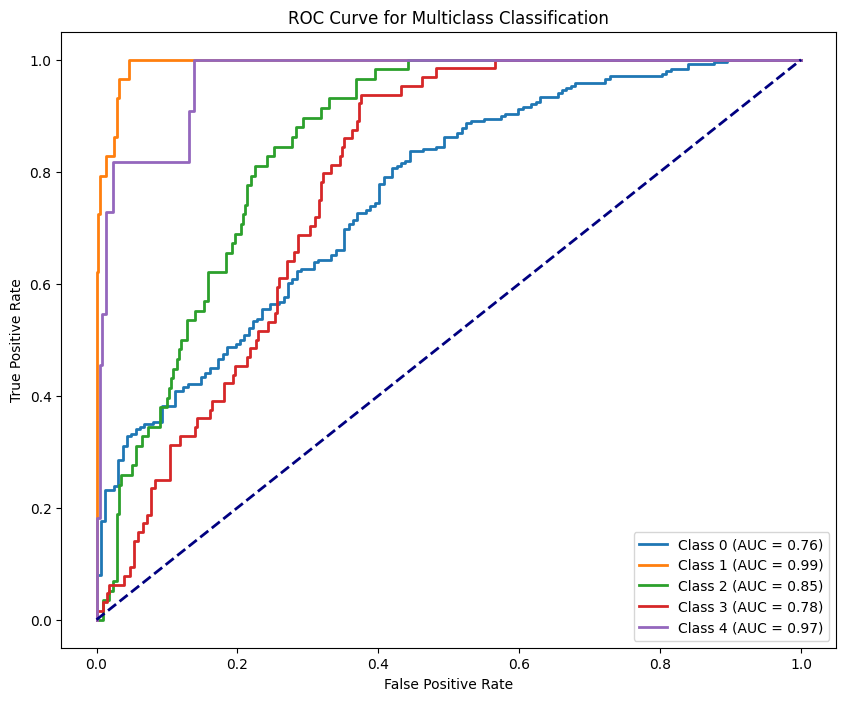

In [33]:
# Binarize the output labels
y_test_bin = label_binarize(y_test_lr, classes=best_lr_model.classes_)

# Get the predicted probabilities for each class
y_pred_prob = best_lr_model.predict_proba(X_test_lr)

# Plot ROC curves for each class
plt.figure(figsize=(10, 8))

for i in range(y_test_bin.shape[1]):
    fpr, tpr, thresholds = roc_curve(y_test_bin[:, i], y_pred_prob[:, i])
    roc_auc = auc(fpr, tpr)
    print(f"Class {best_lr_model.classes_[i]}: AUC = {roc_auc:.4f}")
    plt.plot(fpr, tpr, lw=2, label=f'Class {best_lr_model.classes_[i]} (AUC = {roc_auc:.2f})')

# Plot the diagonal line (chance level)
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve for Multiclass Classification')
plt.legend(loc='lower right')
plt.show()

## learning curve

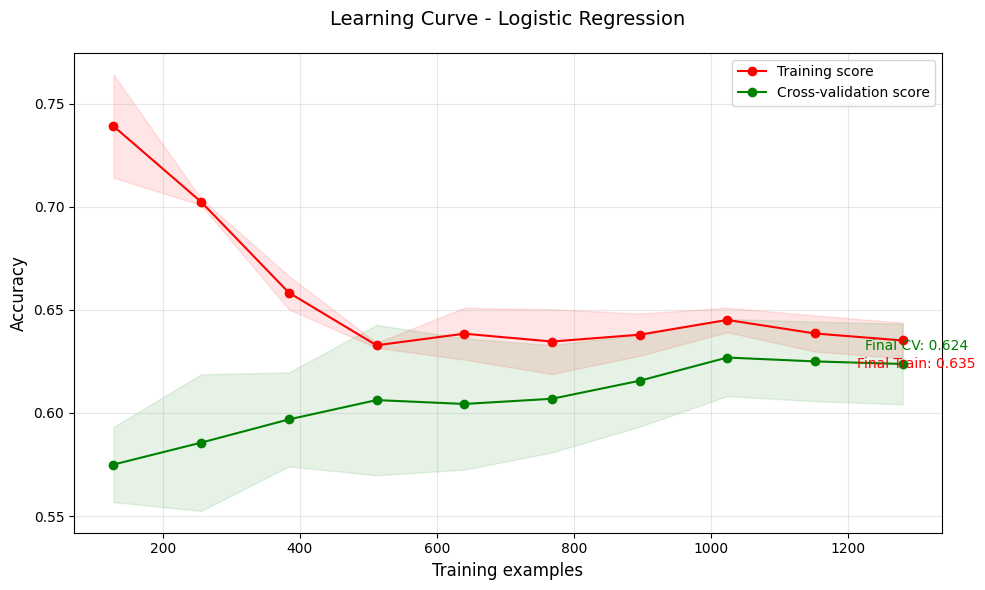

In [34]:
from sklearn.model_selection import learning_curve
import matplotlib.pyplot as plt
import numpy as np

def plot_learning_curve(estimator, X, y, title="Learning Curve", cv=5, 
                       train_sizes=np.linspace(0.1, 1.0, 10), scoring='accuracy'):
    """
    Plot learning curves for a given estimator.
    """
    # Calculate learning curve data
    train_sizes, train_scores, test_scores = learning_curve(
        estimator, X, y, cv=cv, train_sizes=train_sizes, scoring=scoring,
        n_jobs=-1, random_state=42
    )
    
    # Calculate means and standard deviations
    train_scores_mean = np.mean(train_scores, axis=1)
    train_scores_std = np.std(train_scores, axis=1)
    test_scores_mean = np.mean(test_scores, axis=1)
    test_scores_std = np.std(test_scores, axis=1)
    
    # Create the plot
    plt.figure(figsize=(10, 6))
    plt.fill_between(train_sizes, train_scores_mean - train_scores_std,
                     train_scores_mean + train_scores_std, alpha=0.1, color="r")
    plt.fill_between(train_sizes, test_scores_mean - test_scores_std,
                     test_scores_mean + test_scores_std, alpha=0.1, color="g")
    plt.plot(train_sizes, train_scores_mean, 'o-', color="r", label="Training score")
    plt.plot(train_sizes, test_scores_mean, 'o-', color="g", label="Cross-validation score")
    
    # Formatting
    plt.xlabel("Training examples", fontsize=12)
    plt.ylabel("Accuracy", fontsize=12)
    plt.title(title, fontsize=14, pad=20)
    plt.legend(loc="best")
    plt.grid(True, alpha=0.3)
    
    # Add final score annotations
    final_train_score = train_scores_mean[-1]
    final_test_score = test_scores_mean[-1]
    plt.annotate(f'Final Train: {final_train_score:.3f}', 
                 xy=(train_sizes[-1], final_train_score), 
                 xytext=(10, -20), textcoords='offset points',
                 ha='center', fontsize=10, color='red')
    plt.annotate(f'Final CV: {final_test_score:.3f}', 
                 xy=(train_sizes[-1], final_test_score), 
                 xytext=(10, 10), textcoords='offset points',
                 ha='center', fontsize=10, color='green')
    
    plt.tight_layout()
    plt.show()
    
    return train_sizes, train_scores_mean, test_scores_mean

# Usage for your Logistic Regression model
train_sizes, train_scores, test_scores = plot_learning_curve(
    best_lr_model, 
    X_train_lr,  # Use your training data
    y_train_lr,
    title="Learning Curve - Logistic Regression"
)

# Random Forest

## Basic:

In [35]:
# Step 1: Data Preparation
X_train_rf, X_test_rf, y_train_rf, y_test_rf = train_test_split(X, y, test_size=0.2, random_state=42)

# Step 2: Model Initialization
rf_model = RandomForestClassifier(random_state=42)

# Step 3: Training
rf_model.fit(X_train_rf, y_train_rf)

# Step 4: Evaluation
rf_y_pred = rf_model.predict(X_test_rf)
rf_y_pred_proba = rf_model.predict_proba(X_test_rf)

# Step 5: Display
print(f"Accuracy for Random Forest: {accuracy_score(y_test_rf, rf_y_pred):.2f}","\n")
print("Classification Report for Random Forest:")
print(classification_report(y_test_rf, rf_y_pred),"\n")
print("Confusion Matrix for Random Forest:")
print(confusion_matrix(y_test_rf, rf_y_pred))

Accuracy for Random Forest: 0.92 

Classification Report for Random Forest:
              precision    recall  f1-score   support

           0       0.91      0.99      0.95       238
           1       1.00      1.00      1.00        29
           2       0.94      0.83      0.88        58
           3       0.93      0.80      0.86        64
           4       0.83      0.45      0.59        11

    accuracy                           0.92       400
   macro avg       0.92      0.81      0.86       400
weighted avg       0.92      0.92      0.92       400
 

Confusion Matrix for Random Forest:
[[236   0   0   2   0]
 [  0  29   0   0   0]
 [ 10   0  48   0   0]
 [ 10   0   2  51   1]
 [  3   0   1   2   5]]


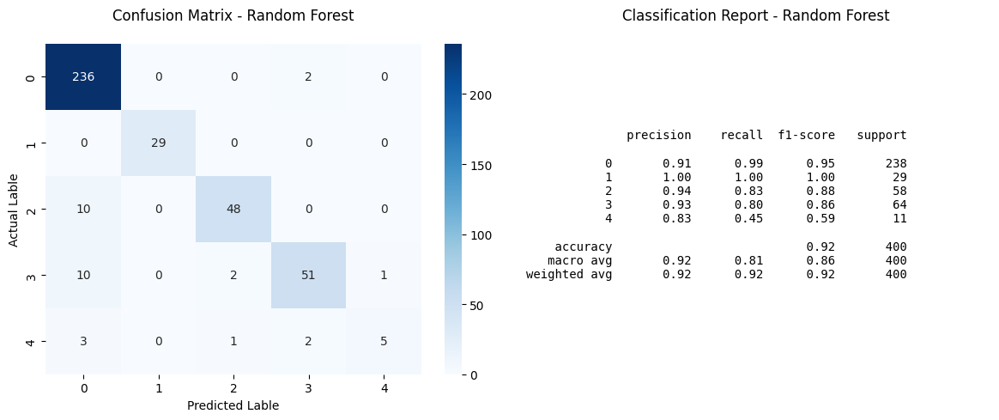

In [36]:
plot_model_performance(y_test_rf, rf_y_pred, model_name="Random Forest")

## Feature Importances

Feature Importance:
               Feature  Importance
6   Body_Temperature_C    0.239753
9  Oxygen_Saturation_%    0.166365
3            Symptom_2    0.120776
4            Symptom_3    0.101175
2            Symptom_1    0.097846
5       Heart_Rate_bpm    0.074168
8            Diastolic    0.063660
7             Systolic    0.063086
0                  Age    0.062732
1       Gender_Encoded    0.010438


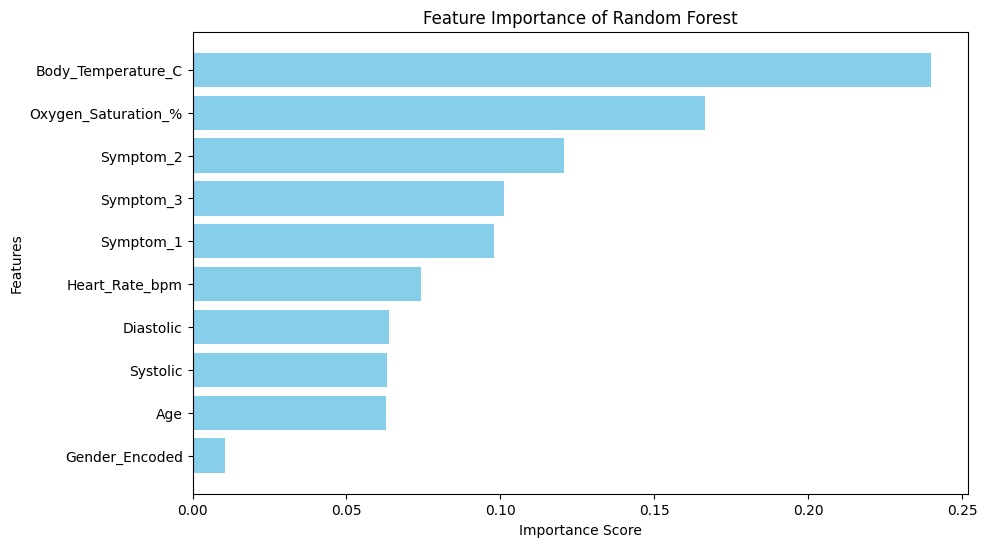

In [37]:
# Get feature importances from the trained model
importances = rf_model.feature_importances_

# Create a DataFrame for feature importance
feature_importances = pd.DataFrame({
    'Feature': X.columns,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

# Display the feature importance
print("Feature Importance:")
print(feature_importances)

# Step 7: Plot the feature importances
plt.figure(figsize=(10, 6))
plt.barh(feature_importances['Feature'], feature_importances['Importance'], color='skyblue')
plt.gca().invert_yaxis()  
plt.title('Feature Importance of Random Forest')
plt.xlabel('Importance Score')
plt.ylabel('Features')
plt.show()

## Grid Search: 

In [38]:
# Step 2: Model Initialization and Grid Search Setup

# Define Hyperparameters for Grid Search
r = {
    'class_weight': [None, 'balanced'],
    'max_depth': [None, 10, 20, 30],
    'max_features': ['sqrt', None],
    'min_samples_leaf': [1, 2, 4],
    'min_samples_split': [2, 5, 10],
    'n_estimators': [200, 300, 400, 500, 600],
}
rf_param_grid = {'class_weight': [None], 'max_depth': [None], 'max_features': [None], 'min_samples_leaf': [1], 'min_samples_split': [2], 'n_estimators': [400]}

# Define Random Forest Model
rf_model = RandomForestClassifier(random_state=42)

# Initialize GridSearchCV
rf_grid_search = GridSearchCV(
    rf_model,
    rf_param_grid, 
    cv=3, 
    scoring='accuracy', 
    verbose=2, 
    n_jobs=-1
)

# Step 3: Training
rf_grid_search.fit(X_train_rf, y_train_rf)

# Step 4: Evaluation
best_rf_model = rf_grid_search.best_estimator_
y_pred_rf = best_rf_model.predict(X_test_rf)
y_pred_rf_proba = best_rf_model.predict_proba(X_test_rf)

# Step 5: Display
print(f"Accuracy for Random Forest: {accuracy_score(y_test_rf, y_pred_rf):.2f}","\n")
print("Best Parameters for Random Forest:")
print(rf_grid_search.best_params_,"\n")
print("Classification Report for Random Forest:")
print(classification_report(y_test_rf, y_pred_rf),"\n")
print("Confusion Matrix for Random Forest:")
print(confusion_matrix(y_test_rf, y_pred_rf))


Fitting 3 folds for each of 1 candidates, totalling 3 fits
Accuracy for Random Forest: 0.96 

Best Parameters for Random Forest:
{'class_weight': None, 'max_depth': None, 'max_features': None, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 400} 

Classification Report for Random Forest:
              precision    recall  f1-score   support

           0       0.97      0.99      0.98       238
           1       1.00      1.00      1.00        29
           2       0.98      0.93      0.96        58
           3       0.92      0.91      0.91        64
           4       0.78      0.64      0.70        11

    accuracy                           0.96       400
   macro avg       0.93      0.89      0.91       400
weighted avg       0.96      0.96      0.96       400
 

Confusion Matrix for Random Forest:
[[236   0   0   1   1]
 [  0  29   0   0   0]
 [  2   0  54   2   0]
 [  5   0   0  58   1]
 [  1   0   1   2   7]]


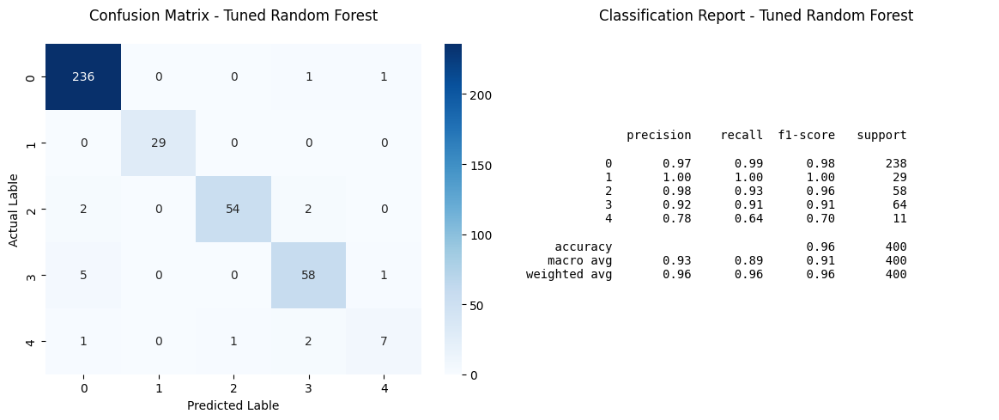

In [39]:
plot_model_performance(y_test_rf, y_pred_rf, model_name="Tuned Random Forest")

## Feature Importances

Feature Importance:
               Feature  Importance
6   Body_Temperature_C    0.203760
9  Oxygen_Saturation_%    0.178204
3            Symptom_2    0.172408
4            Symptom_3    0.162911
2            Symptom_1    0.160099
5       Heart_Rate_bpm    0.046033
8            Diastolic    0.026982
7             Systolic    0.024092
0                  Age    0.022999
1       Gender_Encoded    0.002510


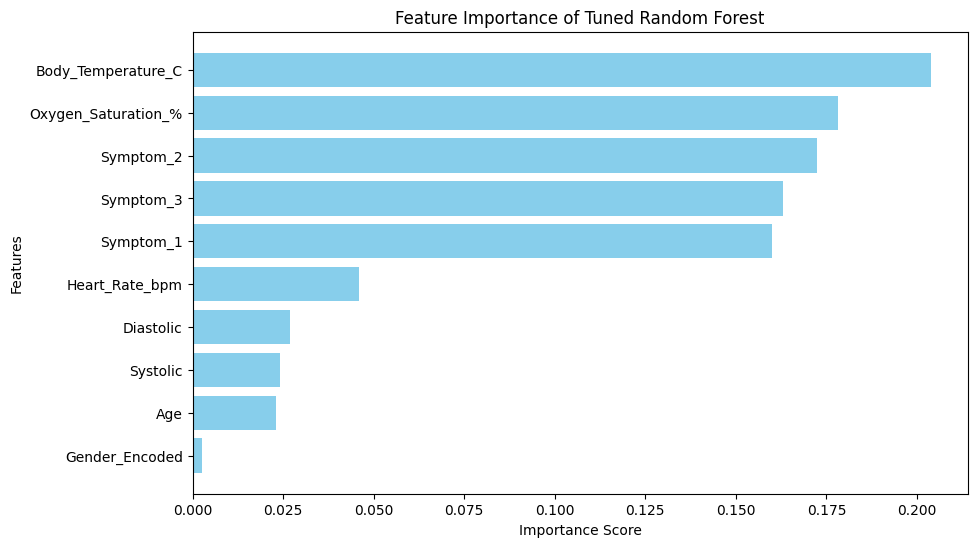

In [40]:
# Get feature importances from the best model
importances = best_rf_model.feature_importances_

# Create a DataFrame for feature importance
feature_importances = pd.DataFrame({
    'Feature': X_train_rf.columns,  # Use X_train_rf to get correct feature names
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

# Display the feature importance
print("Feature Importance:")
print(feature_importances)

# Plot the feature importances
plt.figure(figsize=(10, 6))
plt.barh(feature_importances['Feature'], feature_importances['Importance'], color='skyblue')
plt.gca().invert_yaxis()  
plt.title('Feature Importance of Tuned Random Forest')
plt.xlabel('Importance Score')
plt.ylabel('Features')
plt.show()

# XGBoost

## Basic

In [41]:
# Step 1: Data Preparation
X_train_xgb, X_test_xgb, y_train_xgb, y_test_xgb = train_test_split(X, y, test_size=0.2, random_state=42)

# Step 2: Model Initialization
xgb_model = XGBClassifier(random_state=42, eval_metric='logloss', enable_categorical=True)

# Step 3: Training
xgb_model.fit(X_train_xgb, y_train_xgb)

# Step 4: Evaluation
xgb_y_pred = xgb_model.predict(X_test_xgb)
xgb_y_pred_proba = xgb_model.predict_proba(X_test_xgb)

# Step 5: Display
print(f"Accuracy for XGBoost: {accuracy_score(y_test_xgb, xgb_y_pred):}","\n")
print("Classification Report for XGBoost:")
print(classification_report(y_test_xgb, xgb_y_pred),"\n")
print("Confusion Matrix for XGBoost:")
print(confusion_matrix(y_test_xgb, xgb_y_pred))


Accuracy for XGBoost: 0.9975 

Classification Report for XGBoost:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       238
           1       1.00      1.00      1.00        29
           2       1.00      1.00      1.00        58
           3       0.98      1.00      0.99        64
           4       1.00      0.91      0.95        11

    accuracy                           1.00       400
   macro avg       1.00      0.98      0.99       400
weighted avg       1.00      1.00      1.00       400
 

Confusion Matrix for XGBoost:
[[238   0   0   0   0]
 [  0  29   0   0   0]
 [  0   0  58   0   0]
 [  0   0   0  64   0]
 [  0   0   0   1  10]]


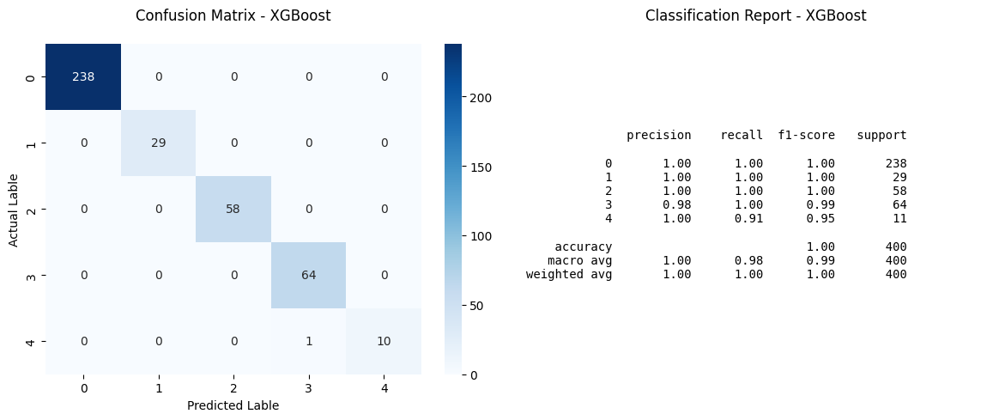

In [42]:
plot_model_performance(y_test_xgb, xgb_y_pred, model_name="XGBoost")

## Feature Importance

Feature Importance:
               Feature  Importance
4            Symptom_3    0.210989
2            Symptom_1    0.210743
9  Oxygen_Saturation_%    0.197983
3            Symptom_2    0.179584
6   Body_Temperature_C    0.158442
5       Heart_Rate_bpm    0.027848
0                  Age    0.011458
8            Diastolic    0.001787
7             Systolic    0.001166
1       Gender_Encoded    0.000000


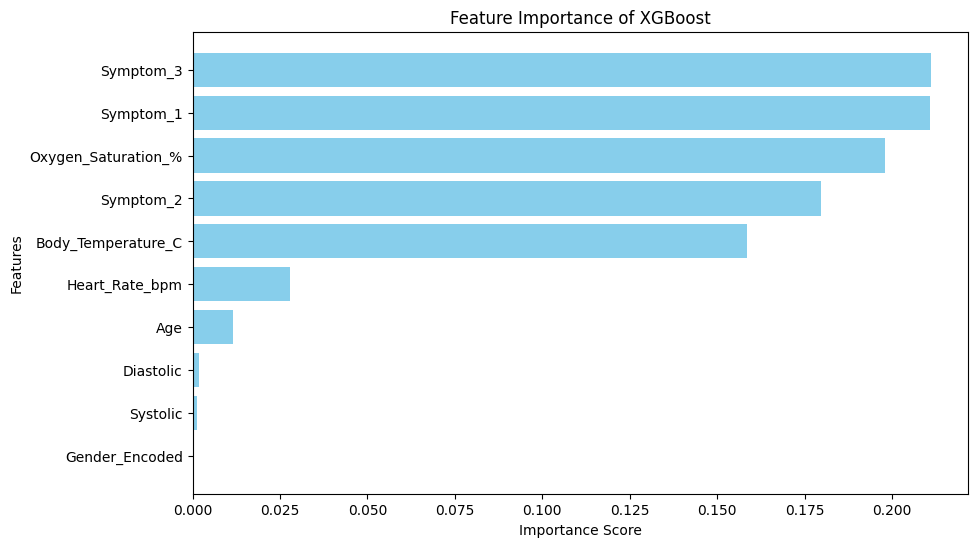

In [43]:
# Get feature importances from the trained model
importances = xgb_model.feature_importances_

# Create a DataFrame for feature importance
feature_importances = pd.DataFrame({
    'Feature': X.columns,  # Use X to get correct feature names
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

# Display the feature importance
print("Feature Importance:")
print(feature_importances)

# Step 7: Plot the feature importances
plt.figure(figsize=(10, 6))
plt.barh(feature_importances['Feature'], feature_importances['Importance'], color='skyblue')
plt.gca().invert_yaxis()  
plt.title('Feature Importance of XGBoost')
plt.xlabel('Importance Score')
plt.ylabel('Features')
plt.show()

## Grid Search

In [44]:
# Step 2: Model Initialization and Grid Search Setup
# Define Hyperparameters for Grid Search
x = {
    'n_estimators': [100, 200, 300],
    'max_depth': [3, 5, 7],
    'learning_rate': [0.01, 0.1, 0.2],
    'subsample': [0.8, 1.0],
    'colsample_bytree': [0.8, 1.0]
}

xgb_param_grid = {'colsample_bytree': [0.8], 'learning_rate': [0.1], 'max_depth': [3], 'n_estimators': [300], 'subsample': [1.0]} 

# Define XGBoost Model
xgb_model = XGBClassifier(random_state=42, eval_metric='logloss', enable_categorical=True)

# Initialize GridSearchCV
xgb_grid_search = GridSearchCV(
    xgb_model,
    xgb_param_grid, 
    cv=5, 
    scoring='accuracy', 
    verbose=2, 
    n_jobs=-1
)

# Step 3: Training
xgb_grid_search.fit(X_train_xgb, y_train_xgb)

# Step 4: Evaluation
best_xgb_model = xgb_grid_search.best_estimator_
y_pred_xgb = best_xgb_model.predict(X_test_xgb)
y_pred_xgb_proba = best_xgb_model.predict_proba(X_test_xgb)

# Step 5: Display
print(f"Accuracy for XGBoost: {accuracy_score(y_test_xgb, y_pred_xgb):}","\n")
print("Best Parameters for XGBoost:")
print(xgb_grid_search.best_params_,"\n")
print("Classification Report for XGBoost:")
print(classification_report(y_test_xgb, y_pred_xgb),"\n")
print("Confusion Matrix for XGBoost:")
print(confusion_matrix(y_test_xgb, y_pred_xgb))

Fitting 5 folds for each of 1 candidates, totalling 5 fits
Accuracy for XGBoost: 1.0 

Best Parameters for XGBoost:
{'colsample_bytree': 0.8, 'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 300, 'subsample': 1.0} 

Classification Report for XGBoost:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       238
           1       1.00      1.00      1.00        29
           2       1.00      1.00      1.00        58
           3       1.00      1.00      1.00        64
           4       1.00      1.00      1.00        11

    accuracy                           1.00       400
   macro avg       1.00      1.00      1.00       400
weighted avg       1.00      1.00      1.00       400
 

Confusion Matrix for XGBoost:
[[238   0   0   0   0]
 [  0  29   0   0   0]
 [  0   0  58   0   0]
 [  0   0   0  64   0]
 [  0   0   0   0  11]]


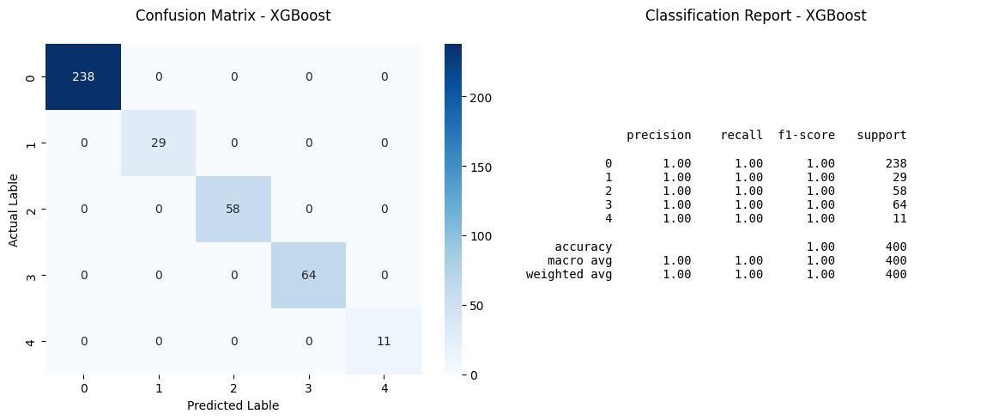

In [45]:
plot_model_performance(y_test_xgb, y_pred_xgb, model_name="XGBoost")

## Feature Importance

Feature Importance:
               Feature  Importance
6   Body_Temperature_C    0.223369
9  Oxygen_Saturation_%    0.213586
3            Symptom_2    0.162447
4            Symptom_3    0.160760
2            Symptom_1    0.153447
5       Heart_Rate_bpm    0.055473
8            Diastolic    0.010436
7             Systolic    0.008205
0                  Age    0.007733
1       Gender_Encoded    0.004544


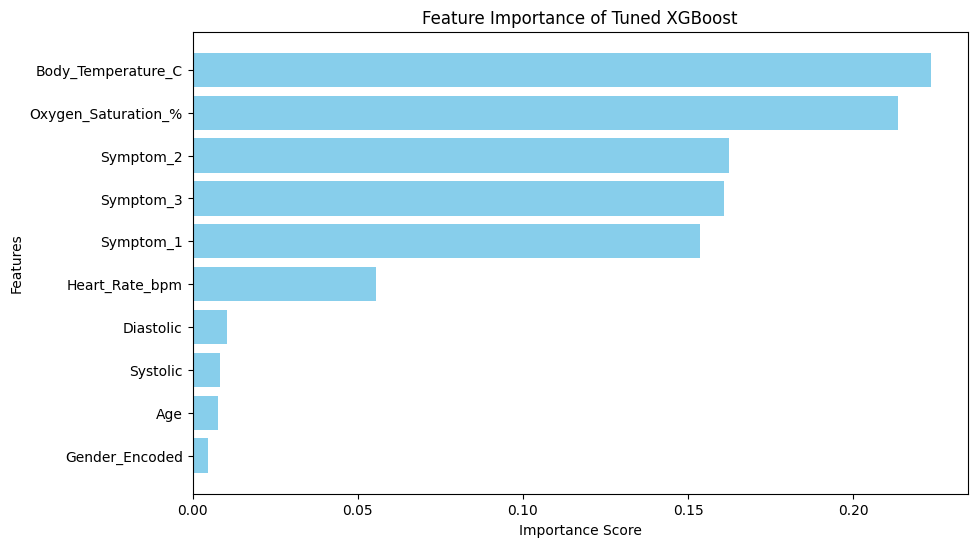

In [46]:
# Get feature importances from the best model
importances = best_xgb_model.feature_importances_

# Create a DataFrame for feature importance
feature_importances = pd.DataFrame({
    'Feature': X.columns,  # Use X to get correct feature names
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

# Display the feature importance
print("Feature Importance:")
print(feature_importances)

# Step 7: Plot the feature importances
plt.figure(figsize=(10, 6))
plt.barh(feature_importances['Feature'], feature_importances['Importance'], color='skyblue')
plt.gca().invert_yaxis()  
plt.title('Feature Importance of Tuned XGBoost')
plt.xlabel('Importance Score')
plt.ylabel('Features')
plt.show()

## Checking The Possibility Of overfitting

### Evaluate Performance on Training Data

In [47]:
y_train_pred_xgb = best_xgb_model.predict(X_train_xgb)
print("Training Accuracy:", accuracy_score(y_train_xgb, y_train_pred_xgb))

Training Accuracy: 1.0


### Use Cross-Validation

In [48]:
cv_scores = cross_val_score(best_xgb_model, X, y, cv=5, scoring='accuracy')
print("Cross-Validation Accuracy:", cv_scores.mean())

Cross-Validation Accuracy: 0.9995


### Visualize Learning Curves

[0]	validation_0-mlogloss:1.47959	validation_1-mlogloss:1.48525
[2]	validation_0-mlogloss:1.24855	validation_1-mlogloss:1.26231
[4]	validation_0-mlogloss:1.08625	validation_1-mlogloss:1.10620
[6]	validation_0-mlogloss:0.94122	validation_1-mlogloss:0.95793
[8]	validation_0-mlogloss:0.82713	validation_1-mlogloss:0.84158
[10]	validation_0-mlogloss:0.73268	validation_1-mlogloss:0.74768
[12]	validation_0-mlogloss:0.65269	validation_1-mlogloss:0.66852
[14]	validation_0-mlogloss:0.59003	validation_1-mlogloss:0.60716
[16]	validation_0-mlogloss:0.53244	validation_1-mlogloss:0.54971
[18]	validation_0-mlogloss:0.48171	validation_1-mlogloss:0.49841
[20]	validation_0-mlogloss:0.43779	validation_1-mlogloss:0.45375
[22]	validation_0-mlogloss:0.39953	validation_1-mlogloss:0.41626
[24]	validation_0-mlogloss:0.36571	validation_1-mlogloss:0.38285
[26]	validation_0-mlogloss:0.34073	validation_1-mlogloss:0.35862
[28]	validation_0-mlogloss:0.31254	validation_1-mlogloss:0.33006
[30]	validation_0-mlogloss:0.2

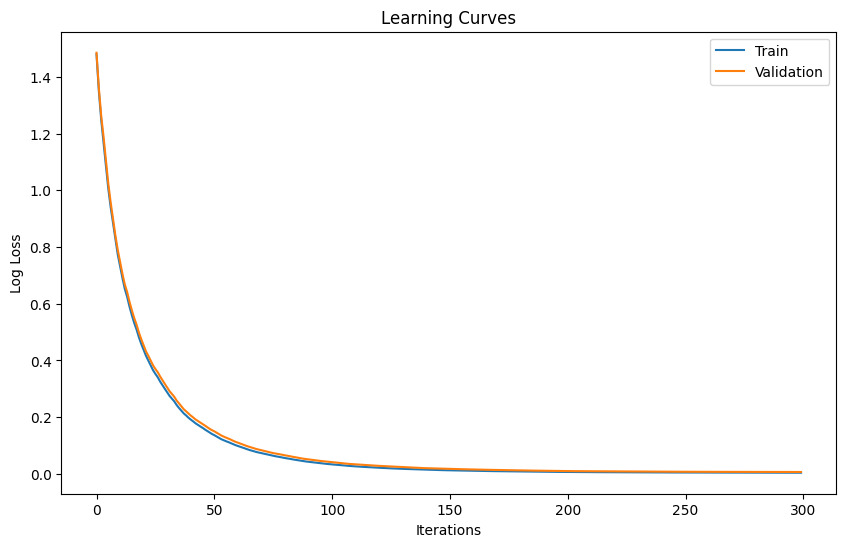

In [49]:
# Split training set further into train and validation sets for monitoring
X_train_sub, X_val, y_train_sub, y_val = train_test_split(X_train_xgb, y_train_xgb, test_size=0.2, random_state=42)

# Define the best hyperparameters from Grid Search
best_params = {
    'colsample_bytree': 0.8,
    'learning_rate': 0.1,
    'max_depth': 3,
    'n_estimators': 300,
    'subsample': 1.0
}

# Train the model with eval_set
best_xgb = XGBClassifier(
    **best_params,  # Unpacking the best parameters
    random_state=42,
    eval_metric='mlogloss',
    enable_categorical=True
)

best_xgb.fit(
    X_train_sub, y_train_sub,
    eval_set=[(X_train_sub, y_train_sub), (X_val, y_val)],
    verbose=2 
)

# Now, evals_result() will work
results = best_xgb.evals_result()

# Plot learning curves
plt.figure(figsize=(10, 6))
plt.plot(results['validation_0']['mlogloss'], label='Train')
plt.plot(results['validation_1']['mlogloss'], label='Validation')
plt.legend()
plt.xlabel("Iterations")
plt.ylabel("Log Loss")
plt.title("Learning Curves")
plt.show()

# Step 4: Evaluation on Test Set
y_pred_xgb = best_xgb.predict(X_test_xgb)

# LightGBM

## Basic

In [50]:
# Step 1: Data Preparation
X_train_lgb, X_test_lgb, y_train_lgb, y_test_lgb = train_test_split(X, y, test_size=0.2, random_state=42)

# Step 2: Model Initialization
lgb_model = LGBMClassifier(random_state=42)

# Step 3: Training
lgb_model.fit(X_train_lgb, y_train_lgb)

# Step 4: Evaluation
lgb_y_pred = lgb_model.predict(X_test_lgb)
lgb_y_pred_proba = lgb_model.predict_proba(X_test_lgb)

# Step 5: Display
print(f"Accuracy for LightGBM: {accuracy_score(y_test_lgb, lgb_y_pred):.2f}","\n")
print("Classification Report for LightGBM:")
print(classification_report(y_test_lgb, lgb_y_pred),"\n")
print("Confusion Matrix for LightGBM:")
print(confusion_matrix(y_test_lgb, lgb_y_pred))


[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000748 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 358
[LightGBM] [Info] Number of data points in the train set: 1600, number of used features: 10
[LightGBM] [Info] Start training from score -0.543650
[LightGBM] [Info] Start training from score -2.479919
[LightGBM] [Info] Start training from score -1.922438
[LightGBM] [Info] Start training from score -1.779337
[LightGBM] [Info] Start training from score -3.881251
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[Lig

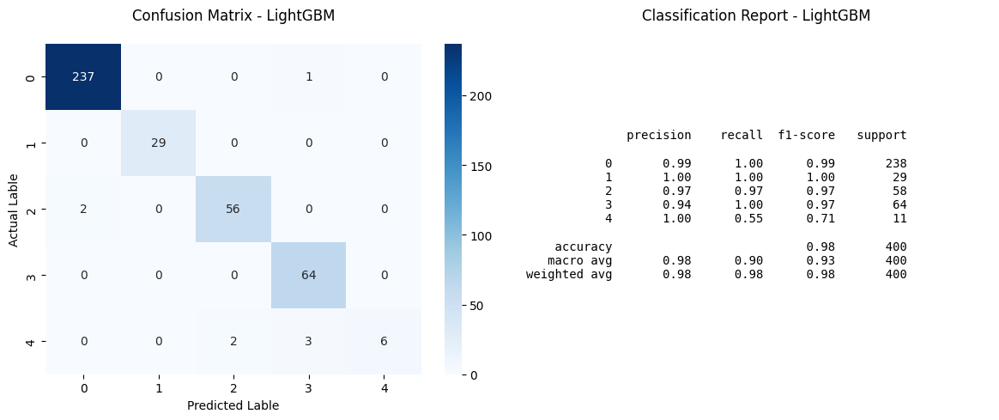

In [51]:
plot_model_performance(y_test_lgb, lgb_y_pred, model_name="LightGBM")

## Feature Importance

Feature Importance:
               Feature  Importance
6   Body_Temperature_C        2935
5       Heart_Rate_bpm        2421
9  Oxygen_Saturation_%        2228
7             Systolic        2138
0                  Age        2119
8            Diastolic        1967
1       Gender_Encoded         327
2            Symptom_1         197
3            Symptom_2         189
4            Symptom_3         187


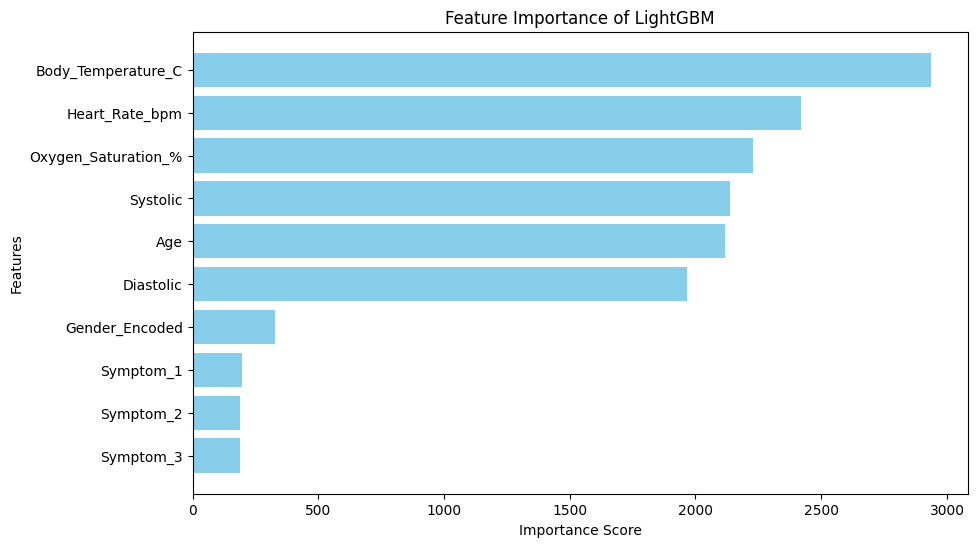

In [52]:
# Step 6: Feature Importance
# Get feature importances from the trained LightGBM model
importances = lgb_model.feature_importances_

# Create a DataFrame for feature importance
feature_importances = pd.DataFrame({
    'Feature': X.columns,  # Use X to get correct feature names
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

# Display the feature importance
print("Feature Importance:")
print(feature_importances)

# Step 7: Plot the feature importances
plt.figure(figsize=(10, 6))
plt.barh(feature_importances['Feature'], feature_importances['Importance'], color='skyblue')
plt.gca().invert_yaxis()  
plt.title('Feature Importance of LightGBM')
plt.xlabel('Importance Score')
plt.ylabel('Features')
plt.show()

## Grid Search

In [53]:
# Step 2: Model Initialization and Grid Search Setup
# Define Hyperparameters for Grid Search
l = {
    'num_leaves': [15, 31, 63],
    'learning_rate': [0.01, 0.1, 0.2],
    'n_estimators': [50, 100, 200],
    'subsample': [0.8, 1.0],
    'colsample_bytree': [0.8, 1.0],
    'force_col_wise': [True]
}

lgb_param_grid = {'colsample_bytree': [1.0], 'force_col_wise': [True], 'learning_rate': [0.1], 'n_estimators': [50], 'num_leaves': [15], 'subsample': [0.8]} 

# Define LightGBM Model
lgb_model = LGBMClassifier(random_state=42)

# Initialize GridSearchCV
lgb_grid_search = GridSearchCV(
    lgb_model,
    lgb_param_grid, 
    cv=5, 
    scoring='accuracy', 
    verbose=2, 
    n_jobs=-1
)

# Step 3: Training
lgb_grid_search.fit(X_train_lgb, y_train_lgb)

# Step 4: Evaluation
best_lgb_model = lgb_grid_search.best_estimator_
y_pred_lgb = best_lgb_model.predict(X_test_lgb)
y_pred_lgb_proba = best_lgb_model.predict_proba(X_test_lgb)

# Step 5: Display
print(f"Accuracy for LightGBM: {accuracy_score(y_test_lgb, y_pred_lgb):.2f}","\n")
print("Best Parameters for LightGBM:")
print(lgb_grid_search.best_params_,"\n")
print("Classification Report for LightGBM:")
print(classification_report(y_test_lgb, y_pred_lgb),"\n")
print("Confusion Matrix for LightGBM:")
print(confusion_matrix(y_test_lgb, y_pred_lgb))


Fitting 5 folds for each of 1 candidates, totalling 5 fits
[LightGBM] [Info] Total Bins 358
[LightGBM] [Info] Number of data points in the train set: 1600, number of used features: 10
[LightGBM] [Info] Start training from score -0.543650
[LightGBM] [Info] Start training from score -2.479919
[LightGBM] [Info] Start training from score -1.922438
[LightGBM] [Info] Start training from score -1.779337
[LightGBM] [Info] Start training from score -3.881251
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
Accuracy for LightGBM: 0.99 

Best Parameters for LightGBM:
{'colsample_bytree': 1.0, 'force_col_wise': True, 'learning_rate': 0.1, 'n_estimators': 50, 'num_leaves': 15, 'subsample': 0.8} 

Classification Report for LightGBM:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       238
           1       1.00      1.00      1.00        29
       

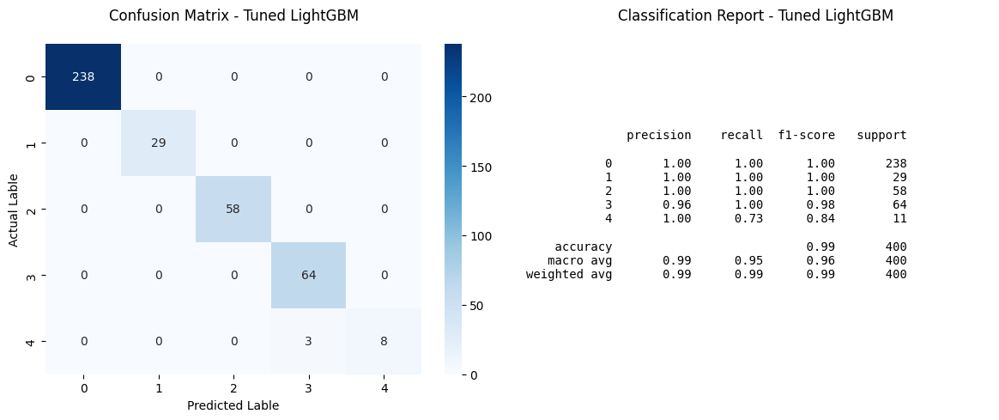

In [54]:
plot_model_performance(y_test_lgb, y_pred_lgb, model_name="Tuned LightGBM")

## Feature Importance

Feature Importance:
               Feature  Importance
6   Body_Temperature_C         909
9  Oxygen_Saturation_%         713
5       Heart_Rate_bpm         538
7             Systolic         326
0                  Age         274
8            Diastolic         263
2            Symptom_1         144
3            Symptom_2         135
4            Symptom_3         128
1       Gender_Encoded          59


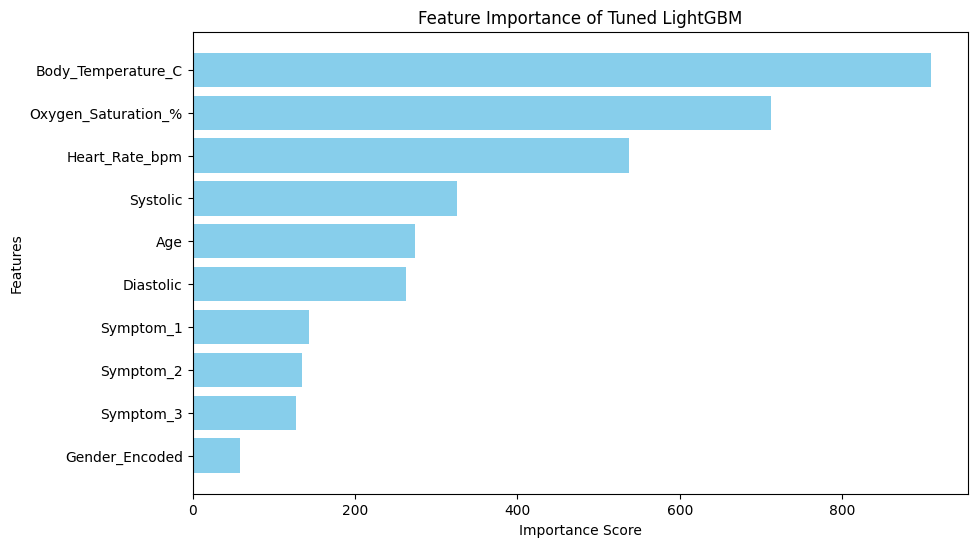

In [55]:
# Get feature importances from the best model obtained from Grid Search
importances = best_lgb_model.feature_importances_

# Create a DataFrame for feature importance
feature_importances = pd.DataFrame({
    'Feature': X.columns,  # Use X to get correct feature names
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

# Display the feature importance
print("Feature Importance:")
print(feature_importances)

# Plot the feature importances
plt.figure(figsize=(10, 6))
plt.barh(feature_importances['Feature'], feature_importances['Importance'], color='skyblue')
plt.gca().invert_yaxis()  
plt.title('Feature Importance of Tuned LightGBM')
plt.xlabel('Importance Score')
plt.ylabel('Features')
plt.show()


# Decision Tree

## Basic

In [56]:
# Step 1: Data Preparation
X_train_dt, X_test_dt, y_train_dt, y_test_dt = train_test_split(X, y, test_size=0.2, random_state=42)

# Step 2: Model Initialization
dt_model = DecisionTreeClassifier(random_state=42)

# Step 3: Training
dt_model.fit(X_train_dt, y_train_dt)

# Step 4: Evaluation
dt_y_pred = dt_model.predict(X_test_dt)
dt_y_pred_proba = dt_model.predict_proba(X_test_dt)

# Step 5: Display
print(f"Accuracy for Decision Tree: {accuracy_score(y_test_dt, dt_y_pred):.2f}", "\n")
print("Classification Report for Decision Tree:")
print(classification_report(y_test_dt, dt_y_pred), "\n")
print("Confusion Matrix for c:")
print(confusion_matrix(y_test_dt, dt_y_pred))


Accuracy for Decision Tree: 0.98 

Classification Report for Decision Tree:
              precision    recall  f1-score   support

           0       0.99      1.00      0.99       238
           1       1.00      1.00      1.00        29
           2       0.97      0.97      0.97        58
           3       0.94      0.94      0.94        64
           4       0.90      0.82      0.86        11

    accuracy                           0.98       400
   macro avg       0.96      0.94      0.95       400
weighted avg       0.98      0.98      0.98       400
 

Confusion Matrix for c:
[[237   0   0   0   1]
 [  0  29   0   0   0]
 [  0   0  56   2   0]
 [  2   0   2  60   0]
 [  0   0   0   2   9]]


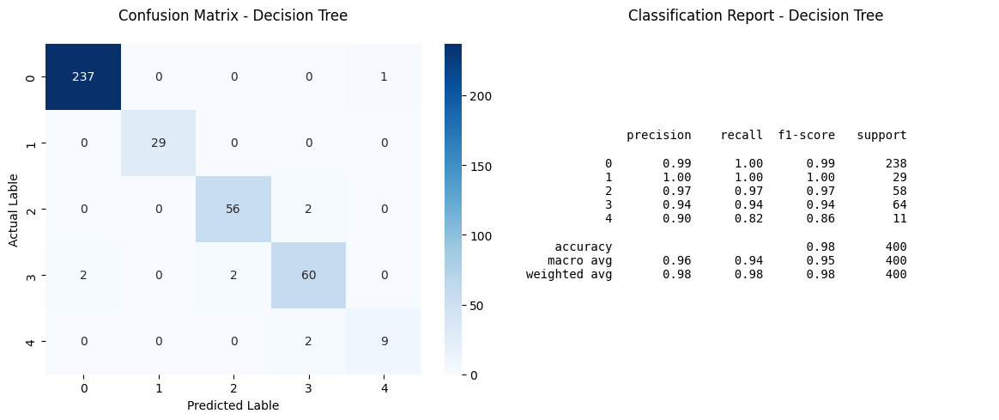

In [57]:
plot_model_performance(y_test_dt, dt_y_pred, model_name="Decision Tree")

## visualization

In [58]:
# Convert feature names and class names to strings
feature_names = X_train_dt.columns.astype(str)
class_names = dt_model.classes_.astype(str)

# Create a much larger figure with adjusted parameters
plt.figure(figsize=(100, 60))
plot_tree(dt_model, 
          feature_names=feature_names, 
          class_names=class_names, 
          filled=True,
          fontsize=12,  # Increase font size
          rounded=True,  # Rounded corners for better appearance
          precision=2)   # Control decimal places
plt.tight_layout()
plt.show()

## Feature Importance

Feature Importance:
               Feature  Importance
6   Body_Temperature_C    0.230149
2            Symptom_1    0.215454
3            Symptom_2    0.195739
4            Symptom_3    0.183681
9  Oxygen_Saturation_%    0.128643
5       Heart_Rate_bpm    0.030131
8            Diastolic    0.012743
0                  Age    0.001892
7             Systolic    0.001569
1       Gender_Encoded    0.000000


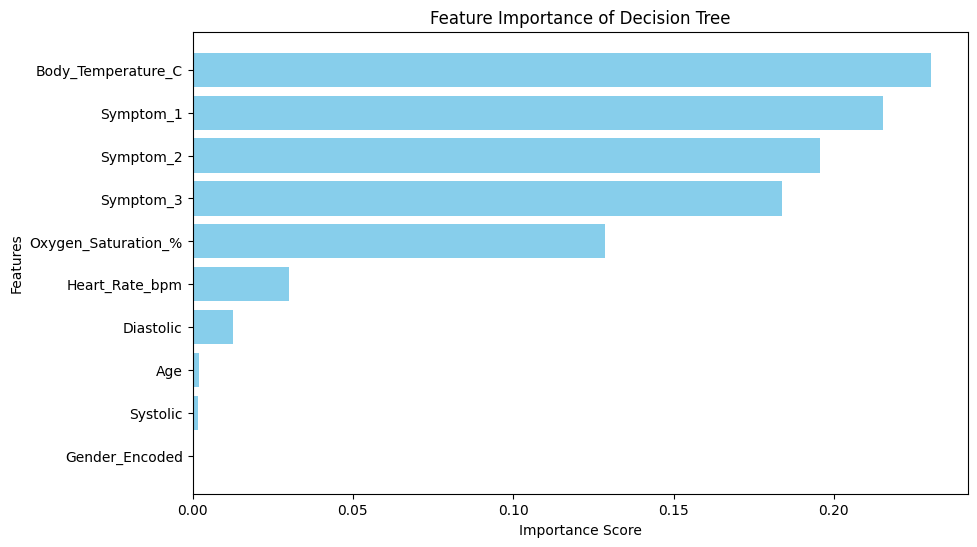

In [59]:
# Get feature importances from the trained Decision Tree model
importances = dt_model.feature_importances_

# Create a DataFrame for feature importance
feature_importances = pd.DataFrame({
    'Feature': X.columns,  # Use X to get correct feature names
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

# Display the feature importance
print("Feature Importance:")
print(feature_importances)

# Plot the feature importances
plt.figure(figsize=(10, 6))
plt.barh(feature_importances['Feature'], feature_importances['Importance'], color='skyblue')
plt.gca().invert_yaxis()  
plt.title('Feature Importance of Decision Tree')
plt.xlabel('Importance Score')
plt.ylabel('Features')
plt.show()


## Grid Search

In [60]:
# Step 2: Model Initialization and Grid Search Setup
# Define Hyperparameters for Grid Search
d = {
    'criterion': ['gini', 'entropy'],
    'max_depth': [3, 5, 10, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
}

dt_param_grid = {'criterion': ['entropy'], 'max_depth': [10], 'min_samples_leaf': [2], 'min_samples_split': [2]} 

# Define Decision Tree Model
dt_model = DecisionTreeClassifier(random_state=42)

# Initialize GridSearchCV
dt_grid_search = GridSearchCV(
    dt_model,
    dt_param_grid, 
    cv=5, 
    scoring='accuracy', 
    verbose=2, 
    n_jobs=-1
)

# Step 3: Training
dt_grid_search.fit(X_train_dt, y_train_dt)

# Step 4: Evaluation
best_dt_model = dt_grid_search.best_estimator_
y_pred_dt = best_dt_model.predict(X_test_dt)
y_pred_dt_proba = best_dt_model.predict_proba(X_test_dt)

# Step 5: Display
print(f"Accuracy for Decision Tree: {accuracy_score(y_test_dt, y_pred_dt):.2f}", "\n")
print("Best Parameters for Decision Tree:")
print(dt_grid_search.best_params_, "\n")
print("Classification Report for Decision Tree:")
print(classification_report(y_test_dt, y_pred_dt), "\n")
print("Confusion Matrix for Decision Tree:")
print(confusion_matrix(y_test_dt, y_pred_dt))


Fitting 5 folds for each of 1 candidates, totalling 5 fits
Accuracy for Decision Tree: 0.96 

Best Parameters for Decision Tree:
{'criterion': 'entropy', 'max_depth': 10, 'min_samples_leaf': 2, 'min_samples_split': 2} 

Classification Report for Decision Tree:
              precision    recall  f1-score   support

           0       0.99      0.98      0.99       238
           1       1.00      1.00      1.00        29
           2       0.92      0.95      0.93        58
           3       0.88      0.88      0.88        64
           4       0.82      0.82      0.82        11

    accuracy                           0.96       400
   macro avg       0.92      0.92      0.92       400
weighted avg       0.96      0.96      0.96       400
 

Confusion Matrix for Decision Tree:
[[234   0   0   3   1]
 [  0  29   0   0   0]
 [  0   0  55   3   0]
 [  2   0   5  56   1]
 [  0   0   0   2   9]]


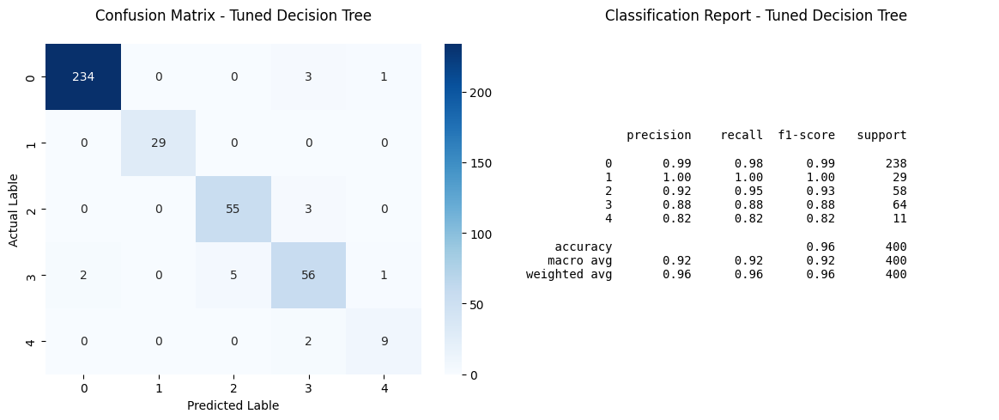

In [61]:
plot_model_performance(y_test_dt, y_pred_dt, model_name="Tuned Decision Tree")

## visualization

In [62]:
# Convert feature names and class names to strings
feature_names = X_train_dt.columns.astype(str)
class_names = best_dt_model.classes_.astype(str)

plt.figure(figsize=(100, 60))
plot_tree(best_dt_model, 
          feature_names=feature_names, 
          class_names=class_names, 
          filled=True,
          fontsize=12,  # Increase font size
          rounded=True,  # Rounded corners for better appearance
          precision=2)   # Control decimal places)
plt.tight_layout()
plt.show()

## Feature Importance

Feature Importance:
               Feature  Importance
6   Body_Temperature_C    0.275306
9  Oxygen_Saturation_%    0.213237
2            Symptom_1    0.174140
3            Symptom_2    0.160303
4            Symptom_3    0.119931
5       Heart_Rate_bpm    0.048464
8            Diastolic    0.004010
7             Systolic    0.003835
0                  Age    0.000774
1       Gender_Encoded    0.000000


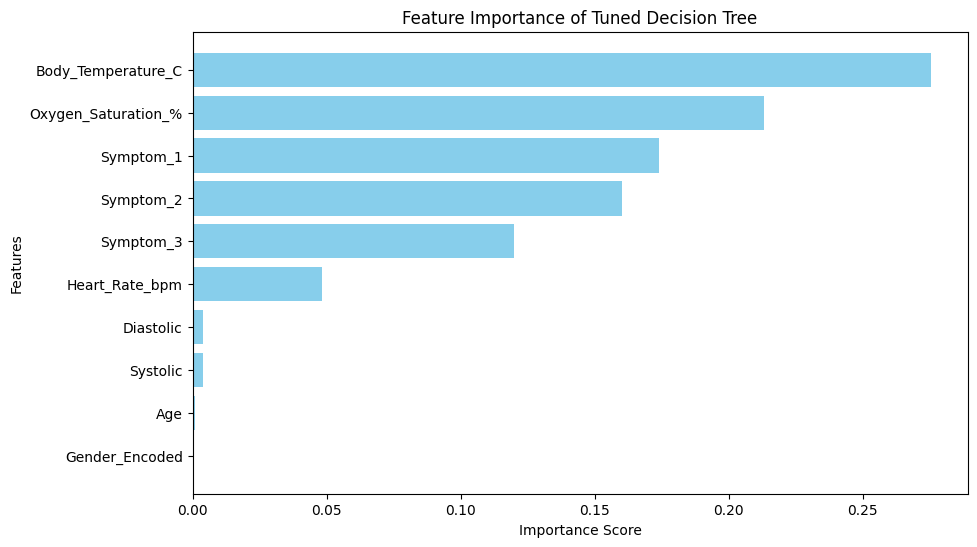

In [63]:
# Get feature importances from the best model obtained from Grid Search
importances = best_dt_model.feature_importances_

# Create a DataFrame for feature importance
feature_importances = pd.DataFrame({
    'Feature': X.columns,  # Use X to get correct feature names
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

# Display the feature importance
print("Feature Importance:")
print(feature_importances)

# Plot the feature importances
plt.figure(figsize=(10, 6))
plt.barh(feature_importances['Feature'], feature_importances['Importance'], color='skyblue')
plt.gca().invert_yaxis()  
plt.title('Feature Importance of Tuned Decision Tree')
plt.xlabel('Importance Score')
plt.ylabel('Features')
plt.show()


## Checking the reason of basic being better than best

### Visualising learning curves

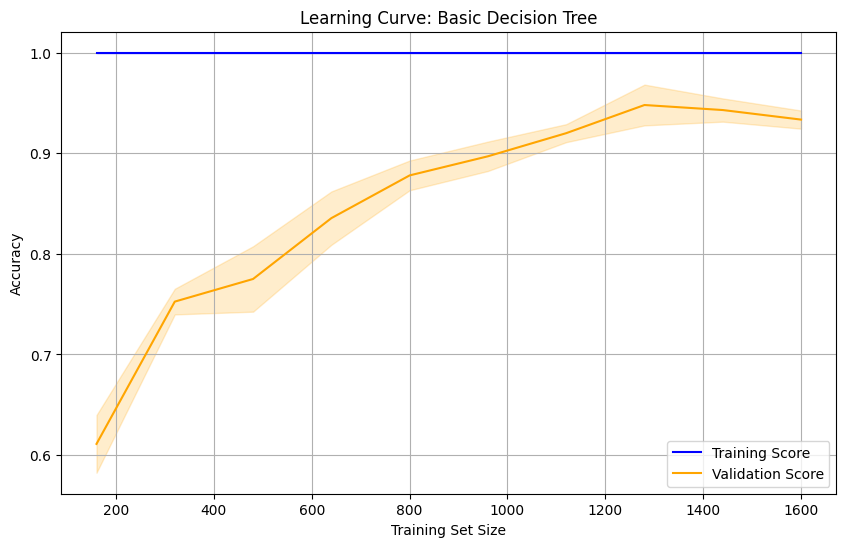

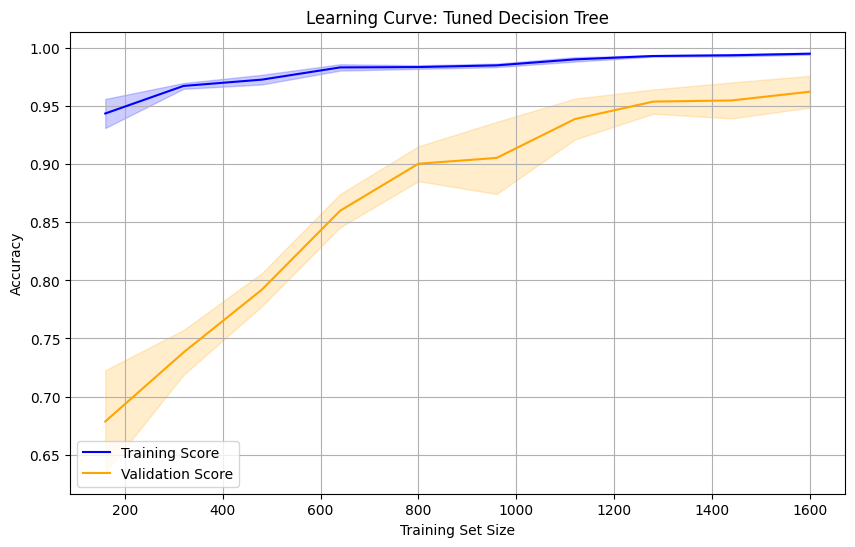

In [64]:
# Function to plot learning curves
def plot_learning_curve(estimator, X, y, title="Learning Curve"):
    train_sizes, train_scores, valid_scores = learning_curve(
        estimator, X, y, cv=5, scoring='accuracy', n_jobs=-1, train_sizes=np.linspace(0.1, 1.0, 10)
    )
    train_mean = np.mean(train_scores, axis=1)
    train_std = np.std(train_scores, axis=1)
    valid_mean = np.mean(valid_scores, axis=1)
    valid_std = np.std(valid_scores, axis=1)

    plt.figure(figsize=(10, 6))
    plt.plot(train_sizes, train_mean, label="Training Score", color="blue")
    plt.fill_between(train_sizes, train_mean - train_std, train_mean + train_std, alpha=0.2, color="blue")
    plt.plot(train_sizes, valid_mean, label="Validation Score", color="orange")
    plt.fill_between(train_sizes, valid_mean - valid_std, valid_mean + valid_std, alpha=0.2, color="orange")
    plt.title(title)
    plt.xlabel("Training Set Size")
    plt.ylabel("Accuracy")
    plt.legend()
    plt.grid()
    plt.show()

# Plot learning curve for the basic model
plot_learning_curve(DecisionTreeClassifier(random_state=42), X, y, title="Learning Curve: Basic Decision Tree")

# Plot learning curve for the tuned model
best_params = dt_grid_search.best_params_
tuned_model = DecisionTreeClassifier(**best_params, random_state=42)
plot_learning_curve(tuned_model, X, y, title="Learning Curve: Tuned Decision Tree")


#### Basic Decision Tree

- It overfits the training data, achieving perfect accuracy on the training set but struggling on the validation set.
- The validation score improves with larger datasets, but the gap remains significant.

#### Tuned Decision Tree

- By adjusting hyperparameters (e.g., limiting tree depth, requiring a minimum number of samples per leaf), the tuned model sacrifices some training accuracy but achieves better validation accuracy.
- It generalizes better to unseen data and shows a more stable learning curve.


### Cross Validation Accuracy Comparison

In [65]:
# Basic model cross-validation
basic_model = DecisionTreeClassifier(random_state=42)
basic_cv_scores = cross_val_score(basic_model, X, y, cv=5, scoring='accuracy')
print(f"Basic Model CV Accuracy: {basic_cv_scores.mean():.2f} ± {basic_cv_scores.std():.2f}")

# Tuned model cross-validation
tuned_cv_scores = cross_val_score(best_dt_model, X, y, cv=5, scoring='accuracy')
print(f"Tuned Model CV Accuracy: {tuned_cv_scores.mean():.2f} ± {tuned_cv_scores.std():.2f}")


Basic Model CV Accuracy: 0.93 ± 0.01
Tuned Model CV Accuracy: 0.96 ± 0.01


### 1. Basic Model CV Accuracy: **0.93 ± 0.01**
- **Mean Accuracy (0.93):**
  - On average, the basic model achieved **93% accuracy** across all cross-validation folds.
  - This is already a relatively good performance, but it might reflect **overfitting** since the basic model tends to memorize the training data.
- **Standard Deviation (± 0.01):**
  - The accuracy varied by **1% (0.01)** between different cross-validation folds.
  - A low standard deviation indicates that the model is **consistent** in its performance across the folds.

---

### 2. Tuned Model CV Accuracy: **0.96 ± 0.01**
- **Mean Accuracy (0.96):**
  - The tuned model achieved a higher mean accuracy of **96%**, showing an improvement over the basic model.
  - This suggests that hyperparameter tuning helped the model **generalize better**, leading to higher performance on unseen data.
- **Standard Deviation (± 0.01):**
  - Like the basic model, the tuned model's accuracy is also **consistent**, with a **1% variability** across folds.

# SVM

## Basic

In [66]:
# Step 1: Data Preparation
X_train_svm, X_test_svm, y_train_svm, y_test_svm = train_test_split(X, y, test_size=0.2, random_state=42)

# Step 2: Model Initialization
svm_model = SVC(probability=True, random_state=42)
# Step 3: Training
svm_model.fit(X_train_svm, y_train_svm)

# Step 4: Evaluation
svm_y_pred = svm_model.predict(X_test_svm)
svm_y_pred_proba = svm_model.predict_proba(X_test_svm)

# Step 5: Display
print(f"Accuracy for SVM: {accuracy_score(y_test_svm, svm_y_pred):.2f}", "\n")
print("Classification Report for SVM:")
print(classification_report(y_test_svm, svm_y_pred), "\n")
print("Confusion Matrix for SVM:")
print(confusion_matrix(y_test_svm, svm_y_pred))


Accuracy for SVM: 0.60 

Classification Report for SVM:
              precision    recall  f1-score   support

           0       0.61      0.99      0.75       238
           1       0.00      0.00      0.00        29
           2       0.00      0.00      0.00        58
           3       0.50      0.11      0.18        64
           4       0.00      0.00      0.00        11

    accuracy                           0.60       400
   macro avg       0.22      0.22      0.19       400
weighted avg       0.44      0.60      0.48       400
 

Confusion Matrix for SVM:
[[235   0   0   3   0]
 [ 29   0   0   0   0]
 [ 57   0   0   1   0]
 [ 57   0   0   7   0]
 [  8   0   0   3   0]]


C:\Users\aylin\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\metrics\_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
C:\Users\aylin\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\metrics\_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
C:\Users\aylin\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\metrics\_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, mo

C:\Users\aylin\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\metrics\_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
C:\Users\aylin\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\metrics\_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
C:\Users\aylin\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\metrics\_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, mo

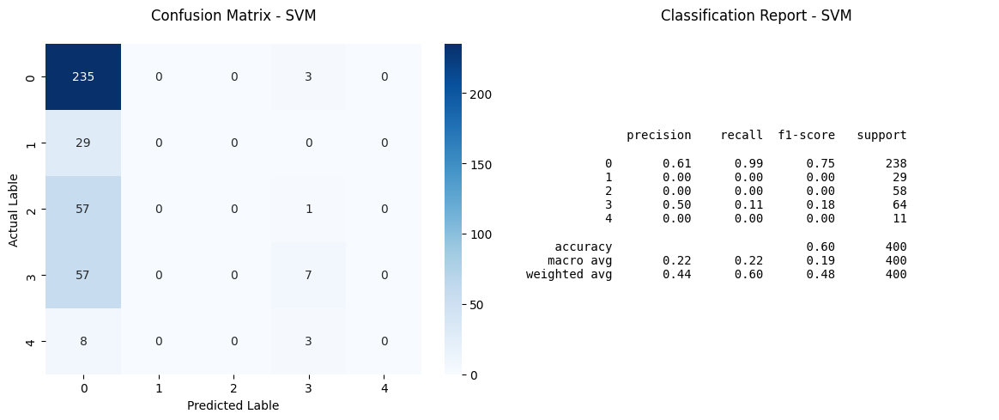

In [67]:
plot_model_performance(y_test_svm, svm_y_pred, model_name="SVM")

## Feature Importance

Feature Importance (Permutation):
               Feature  Importance
9  Oxygen_Saturation_%    0.013583
3            Symptom_2    0.000833
0                  Age    0.000250
5       Heart_Rate_bpm   -0.000083
4            Symptom_3   -0.000750
6   Body_Temperature_C   -0.001500
1       Gender_Encoded   -0.001667
8            Diastolic   -0.001750
2            Symptom_1   -0.002250
7             Systolic   -0.004500


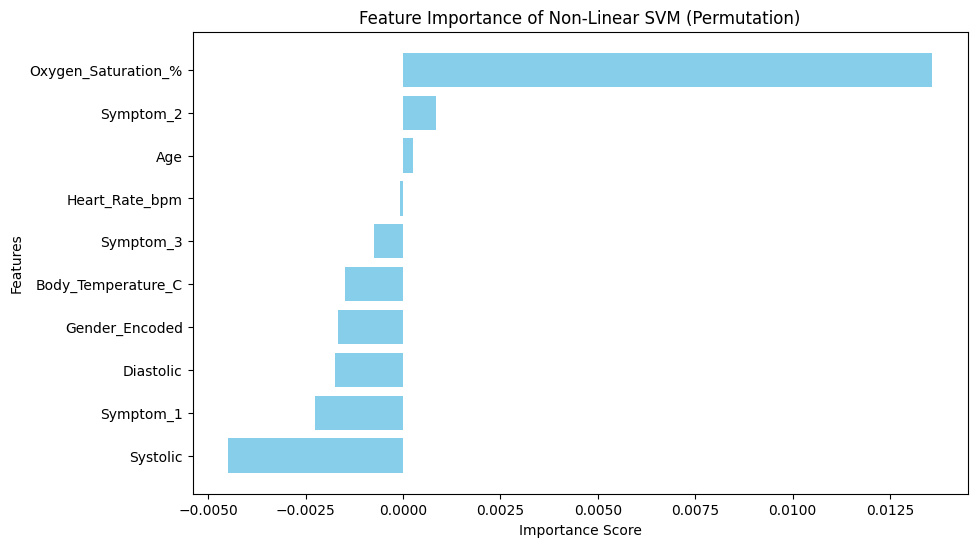

In [68]:
# For non-linear SVM, use permutation importance
result = permutation_importance(svm_model, X_test_svm, y_test_svm, n_repeats=30, random_state=42)

# Create a DataFrame for feature importance
feature_importances = pd.DataFrame({
    'Feature': X.columns,
    'Importance': result.importances_mean
}).sort_values(by='Importance', ascending=False)

# Display the feature importance
print("Feature Importance (Permutation):")
print(feature_importances)

# Step 7: Plot the feature importances
plt.figure(figsize=(10, 6))
plt.barh(feature_importances['Feature'], feature_importances['Importance'], color='skyblue')
plt.gca().invert_yaxis()  
plt.title('Feature Importance of Non-Linear SVM (Permutation)')
plt.xlabel('Importance Score')
plt.ylabel('Features')
plt.show()


## Greed Search

In [69]:
# Step 2: Model Initialization and Grid Search Setup
# Define Hyperparameters for Grid Search
s = {
    'C': [0.1, 1, 10, 15],
    'gamma': [0.001, 0.01, 0.1, 1],
    'kernel': ['rbf', 'linear']
}
svm_param_grid = {'C': [15], 'gamma': [0.1], 'kernel': ['rbf']} 

# Define SVM Model
svm_model = SVC(probability=True, random_state=42)

# Initialize GridSearchCV
svm_grid_search = GridSearchCV(
    svm_model,
    svm_param_grid, 
    cv=5, 
    scoring='accuracy', 
    verbose=2, 
    n_jobs=-1
)

# Step 3: Training
svm_grid_search.fit(X_train_svm, y_train_svm)

# Step 4: Evaluation
best_svm_model = svm_grid_search.best_estimator_
y_pred_svm = best_svm_model.predict(X_test_svm)
y_pred_svm_proba = best_svm_model.predict_proba(X_test_svm)

# Step 5: Display
print(f"Accuracy for SVM: {accuracy_score(y_test_svm, y_pred_svm):.2f}", "\n")
print("Best Parameters for SVM:")
print(svm_grid_search.best_params_, "\n")
print("Classification Report for SVM:")
print(classification_report(y_test_svm, y_pred_svm), "\n")
print("Confusion Matrix for SVM:")
print(confusion_matrix(y_test_svm, y_pred_svm))


Fitting 5 folds for each of 1 candidates, totalling 5 fits
Accuracy for SVM: 0.76 

Best Parameters for SVM:
{'C': 15, 'gamma': 0.1, 'kernel': 'rbf'} 

Classification Report for SVM:
              precision    recall  f1-score   support

           0       0.83      0.86      0.84       238
           1       0.75      0.62      0.68        29
           2       0.62      0.67      0.64        58
           3       0.64      0.61      0.62        64
           4       0.75      0.27      0.40        11

    accuracy                           0.76       400
   macro avg       0.72      0.61      0.64       400
weighted avg       0.76      0.76      0.76       400
 

Confusion Matrix for SVM:
[[205   6  11  16   0]
 [  9  18   0   2   0]
 [ 17   0  39   2   0]
 [ 16   0   8  39   1]
 [  1   0   5   2   3]]


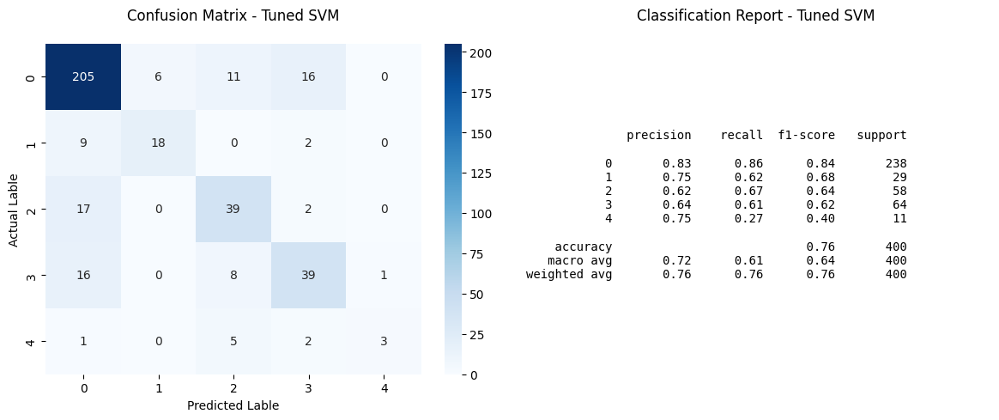

In [70]:
plot_model_performance(y_test_svm, y_pred_svm, model_name="Tuned SVM")

## Feature Importance

Feature Importance (Permutation):
               Feature  Importance
6   Body_Temperature_C    0.156500
9  Oxygen_Saturation_%    0.126667
2            Symptom_1    0.098583
4            Symptom_3    0.095417
3            Symptom_2    0.089250
0                  Age    0.010333
8            Diastolic    0.005167
5       Heart_Rate_bpm    0.002833
1       Gender_Encoded   -0.001750
7             Systolic   -0.004500


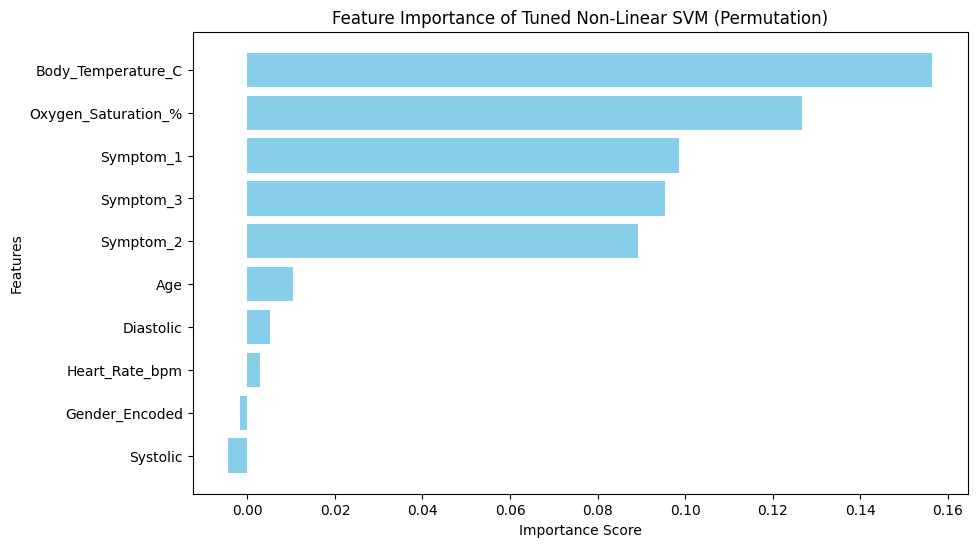

In [71]:
# For non-linear SVM, use permutation importance
result = permutation_importance(best_svm_model, X_test_svm, y_test_svm, n_repeats=30, random_state=42)

# Create a DataFrame for feature importance
feature_importances = pd.DataFrame({
    'Feature': X.columns,
    'Importance': result.importances_mean
}).sort_values(by='Importance', ascending=False)

# Display the feature importance
print("Feature Importance (Permutation):")
print(feature_importances)

# Step 7: Plot the feature importances
plt.figure(figsize=(10, 6))
plt.barh(feature_importances['Feature'], feature_importances['Importance'], color='skyblue')
plt.gca().invert_yaxis()  
plt.title('Feature Importance of Tuned Non-Linear SVM (Permutation)')
plt.xlabel('Importance Score')
plt.ylabel('Features')
plt.show()

# K-NN

## Basic

In [93]:
# Step 1: Data Preparation
X_train_knn, X_test_knn, y_train_knn, y_test_knn = train_test_split(X, y, test_size=0.2, random_state=42)

# Step 2: Model Initialization
knn_model = KNeighborsClassifier(n_neighbors=5)

# Step 3: Training
knn_model.fit(X_train_knn, y_train_knn)

# Step 4: Evaluation
knn_y_pred = knn_model.predict(X_test_knn)
knn_y_pred_proba = knn_model.predict_proba(X_test_knn)

# Step 5: Display
print(f"Accuracy for K-Nearest Neighbors: {accuracy_score(y_test_knn, knn_y_pred):.2f}","\n")
print("Classification Report for K-Nearest Neighbors:")
print(classification_report(y_test_knn, knn_y_pred),"\n")
print("Confusion Matrix for K-Nearest Neighbors:")
print(confusion_matrix(y_test_knn, knn_y_pred))


Accuracy for K-Nearest Neighbors: 0.64 

Classification Report for K-Nearest Neighbors:
              precision    recall  f1-score   support

           0       0.70      0.87      0.77       238
           1       0.17      0.07      0.10        29
           2       0.48      0.41      0.44        58
           3       0.56      0.38      0.45        64
           4       0.00      0.00      0.00        11

    accuracy                           0.64       400
   macro avg       0.38      0.34      0.35       400
weighted avg       0.59      0.64      0.60       400
 

Confusion Matrix for K-Nearest Neighbors:
[[206   5  15  12   0]
 [ 22   2   2   3   0]
 [ 32   0  24   2   0]
 [ 29   5   6  24   0]
 [  6   0   3   2   0]]


C:\Users\aylin\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\metrics\_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
C:\Users\aylin\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\metrics\_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
C:\Users\aylin\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\metrics\_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, mo

C:\Users\aylin\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\metrics\_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
C:\Users\aylin\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\metrics\_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
C:\Users\aylin\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\metrics\_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, mo

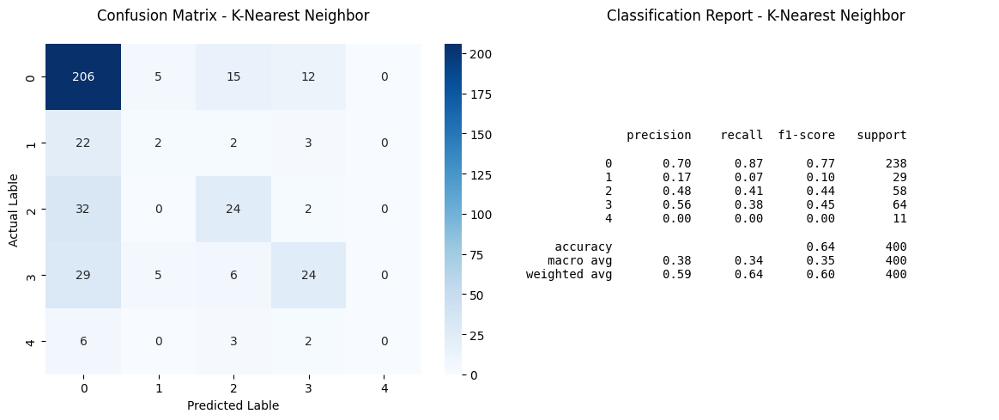

In [94]:
plot_model_performance(y_test_knn, knn_y_pred, model_name="K-Nearest Neighbor")

## Feature Importance

Feature Importance (Permutation):
               Feature  Importance
4            Symptom_3    0.062167
3            Symptom_2    0.050167
2            Symptom_1    0.040667
9  Oxygen_Saturation_%    0.036750
6   Body_Temperature_C    0.029667
7             Systolic    0.002833
8            Diastolic   -0.007583
1       Gender_Encoded   -0.007667
5       Heart_Rate_bpm   -0.008417
0                  Age   -0.010333


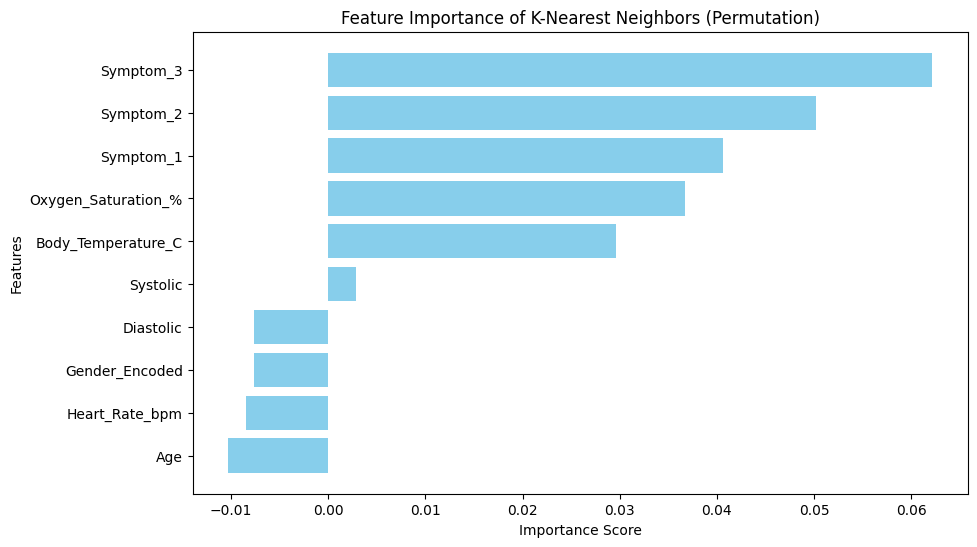

In [95]:
# Calculate permutation importance
result = permutation_importance(knn_model, X_test_knn, y_test_knn, n_repeats=30, random_state=42)

# Create a DataFrame for feature importance
feature_importances = pd.DataFrame({
    'Feature': X.columns,  # Use X to get correct feature names
    'Importance': result.importances_mean
}).sort_values(by='Importance', ascending=False)

# Display the feature importance
print("Feature Importance (Permutation):")
print(feature_importances)

# Plot the feature importances
plt.figure(figsize=(10, 6))
plt.barh(feature_importances['Feature'], feature_importances['Importance'], color='skyblue')
plt.gca().invert_yaxis()  
plt.title('Feature Importance of K-Nearest Neighbors (Permutation)')
plt.xlabel('Importance Score')
plt.ylabel('Features')
plt.show()


## Grid Search

In [96]:
# Step 2: Model Initialization and Grid Search Setup
# Define Hyperparameters for Grid Search
k = {
    'n_neighbors': [3, 5, 9, 10, 11],        
    'weights': ['uniform', 'distance'],
    'metric': ['euclidean', 'manhattan', 'minkowski']
}
knn_param_grid = {'metric': ['manhattan'], 'n_neighbors': [10], 'weights': ['distance']} 

# Define K-Nearest Neighbors Model
knn_model = KNeighborsClassifier()

# Initialize GridSearchCV
knn_grid_search = GridSearchCV(
    knn_model,
    knn_param_grid, 
    cv=5, 
    scoring='accuracy', 
    verbose=2, 
    n_jobs=-1
)

# Step 3: Training
knn_grid_search.fit(X_train_knn, y_train_knn)

# Step 4: Evaluation
best_knn_model = knn_grid_search.best_estimator_
y_pred_knn = best_knn_model.predict(X_test_knn)
y_pred_knn_proba = best_knn_model.predict_proba(X_test_knn)

# Step 5: Display
print(f"Accuracy for K-Nearest Neighbors: {accuracy_score(y_test_knn, y_pred_knn):.2f}","\n")
print("Best Parameters for K-Nearest Neighbors:")
print(knn_grid_search.best_params_,"\n")
print("Classification Report for K-Nearest Neighbors:")
print(classification_report(y_test_knn, y_pred_knn),"\n")
print("Confusion Matrix for K-Nearest Neighbors:")
print(confusion_matrix(y_test_knn, y_pred_knn))


Fitting 5 folds for each of 1 candidates, totalling 5 fits
Accuracy for K-Nearest Neighbors: 0.67 

Best Parameters for K-Nearest Neighbors:
{'metric': 'manhattan', 'n_neighbors': 10, 'weights': 'distance'} 

Classification Report for K-Nearest Neighbors:
              precision    recall  f1-score   support

           0       0.71      0.89      0.79       238
           1       0.57      0.14      0.22        29
           2       0.51      0.34      0.41        58
           3       0.56      0.50      0.53        64
           4       0.00      0.00      0.00        11

    accuracy                           0.67       400
   macro avg       0.47      0.37      0.39       400
weighted avg       0.63      0.67      0.63       400
 

Confusion Matrix for K-Nearest Neighbors:
[[211   1  10  16   0]
 [ 24   4   0   1   0]
 [ 32   0  20   5   1]
 [ 24   2   6  32   0]
 [  5   0   3   3   0]]


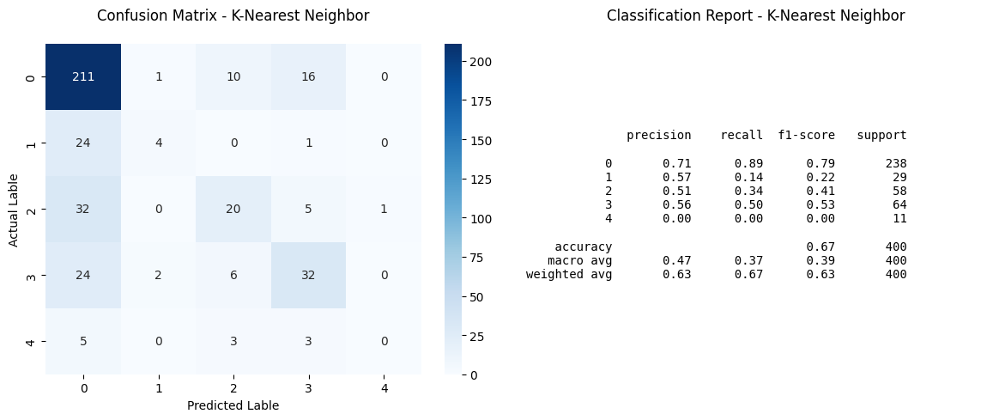

In [97]:
plot_model_performance(y_test_knn, y_pred_knn, model_name="K-Nearest Neighbor")

## Feature Importance

Feature Importance (Permutation):
               Feature  Importance
4            Symptom_3    0.050750
9  Oxygen_Saturation_%    0.049833
3            Symptom_2    0.045833
6   Body_Temperature_C    0.043667
2            Symptom_1    0.039917
7             Systolic   -0.002167
8            Diastolic   -0.002667
0                  Age   -0.012000
5       Heart_Rate_bpm   -0.012833
1       Gender_Encoded   -0.015000


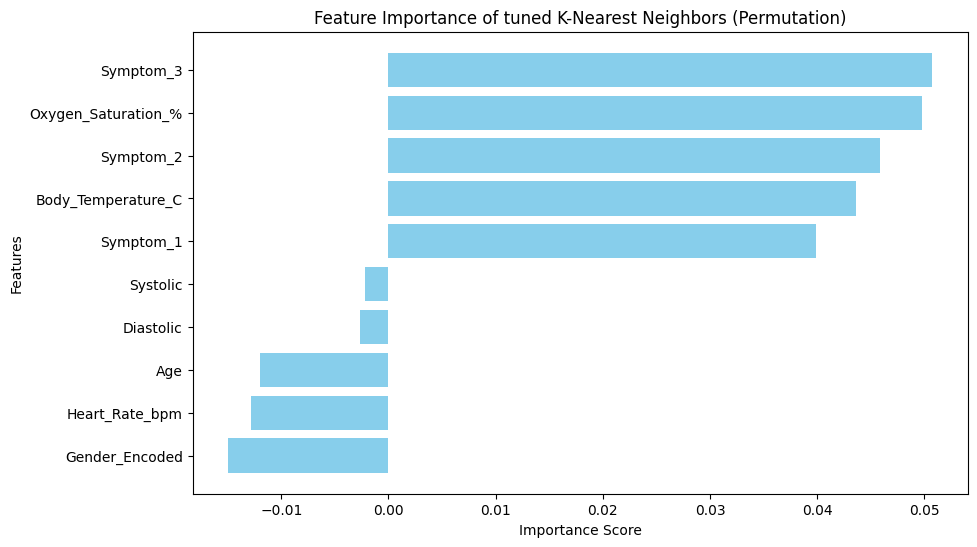

In [98]:
# Calculate permutation importance
result = permutation_importance(best_knn_model, X_test_knn, y_test_knn, n_repeats=30, random_state=42)

# Create a DataFrame for feature importance
feature_importances = pd.DataFrame({
    'Feature': X.columns,  # Use X to get correct feature names
    'Importance': result.importances_mean
}).sort_values(by='Importance', ascending=False)

# Display the feature importance
print("Feature Importance (Permutation):")
print(feature_importances)

# Step 7: Plot the feature importances
plt.figure(figsize=(10, 6))
plt.barh(feature_importances['Feature'], feature_importances['Importance'], color='skyblue')
plt.gca().invert_yaxis()  
plt.title('Feature Importance of tuned K-Nearest Neighbors (Permutation)')
plt.xlabel('Importance Score')
plt.ylabel('Features')
plt.show()


# Naive Bayes

## Basic

In [78]:
# Step 1: Data Preparation
X_train_nb, X_test_nb, y_train_nb, y_test_nb = train_test_split(X, y, test_size=0.2, random_state=42)

# Step 2: Model Initialization
nb_model = GaussianNB()

# Step 3: Training
nb_model.fit(X_train_nb, y_train_nb)

# Step 4: Evaluation
nb_y_pred = nb_model.predict(X_test_nb)
nb_y_pred_proba = nb_model.predict_proba(X_test_nb)

# Step 5: Display
print(f"Accuracy for Naive Bayes: {accuracy_score(y_test_nb, nb_y_pred):.2f}","\n")
print("Classification Report for Naive Bayes:")
print(classification_report(y_test_nb, nb_y_pred),"\n")
print("Confusion Matrix for Naive Bayes:")
print(confusion_matrix(y_test_nb, nb_y_pred))

Accuracy for Naive Bayes: 0.66 

Classification Report for Naive Bayes:
              precision    recall  f1-score   support

           0       0.73      0.80      0.77       238
           1       1.00      0.93      0.96        29
           2       0.41      0.36      0.39        58
           3       0.36      0.31      0.34        64
           4       0.57      0.36      0.44        11

    accuracy                           0.66       400
   macro avg       0.62      0.55      0.58       400
weighted avg       0.64      0.66      0.65       400
 

Confusion Matrix for Naive Bayes:
[[191   0  21  26   0]
 [  2  27   0   0   0]
 [ 30   0  21   7   0]
 [ 32   0   9  20   3]
 [  5   0   0   2   4]]


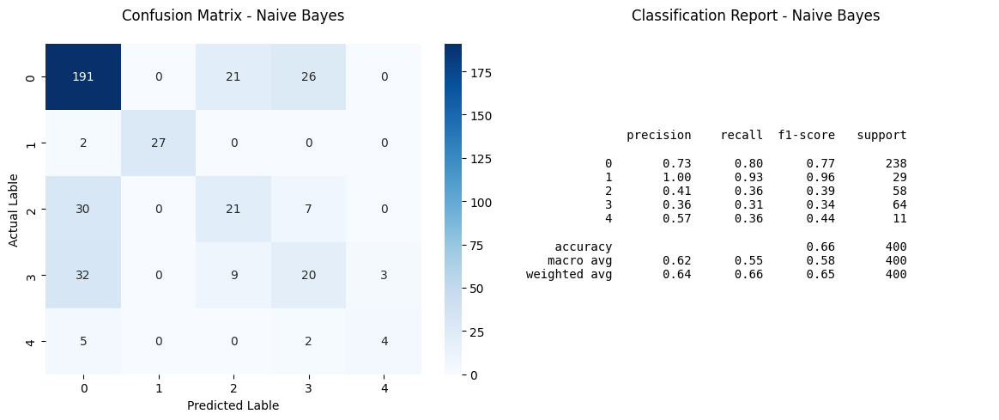

In [79]:
plot_model_performance(y_test_nb, nb_y_pred, model_name="Naive Bayes")

## Feature Importances

Feature Importance (Permutation):
               Feature  Importance
6   Body_Temperature_C    0.135833
9  Oxygen_Saturation_%    0.129167
5       Heart_Rate_bpm    0.020500
4            Symptom_3    0.020333
3            Symptom_2    0.019250
2            Symptom_1    0.013750
1       Gender_Encoded    0.008750
7             Systolic    0.004750
8            Diastolic    0.002167
0                  Age    0.000833


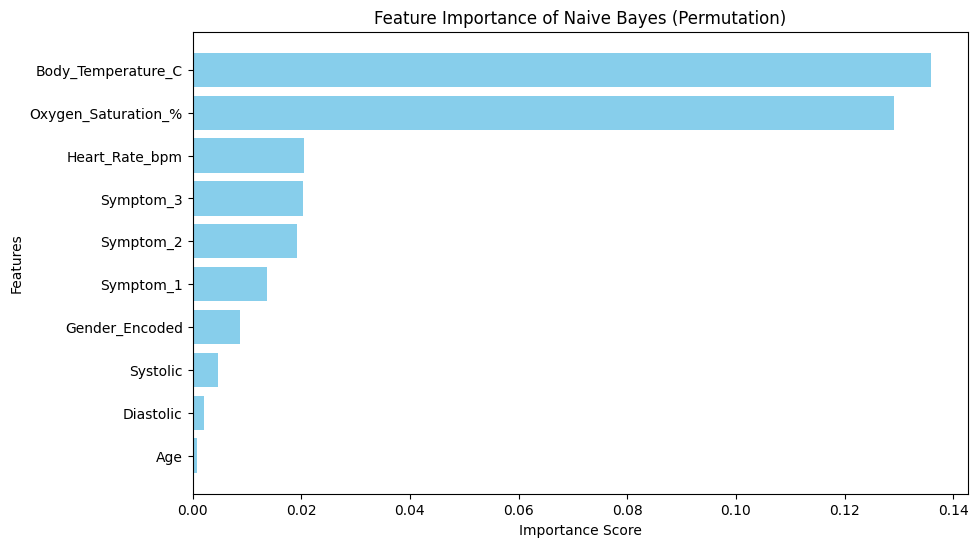

In [91]:
# Calculate permutation importance
result = permutation_importance(nb_model, X_test_nb, y_test_nb, n_repeats=30, random_state=42)

# Create a DataFrame for feature importance
feature_importances = pd.DataFrame({
    'Feature': X.columns,  # Use X to get correct feature names
    'Importance': result.importances_mean
}).sort_values(by='Importance', ascending=False)

# Display the feature importance
print("Feature Importance (Permutation):")
print(feature_importances)

# Step 7: Plot the feature importances
plt.figure(figsize=(10, 6))
plt.barh(feature_importances['Feature'], feature_importances['Importance'], color='skyblue')
plt.gca().invert_yaxis()  
plt.title('Feature Importance of Naive Bayes (Permutation)')
plt.xlabel('Importance Score')
plt.ylabel('Features')
plt.show()


# ANN

In [81]:
# Step 1: Data Preparation
X_train_ann, X_test_ann, y_train_ann, y_test_ann = train_test_split(X, y, test_size=0.2, random_state=42)

# Step 2: Model Initialization
ann_model = Sequential([
    Input(shape=(X_train_ann.shape[1],)),   # Input layer
    Dense(64, activation='relu'),          # Hidden layer 1 with more neurons
    Dropout(0.3),                          # Dropout for regularization
    Dense(32, activation='relu'),          # Hidden layer 2
    BatchNormalization(),                  # Normalize to stabilize training
    Dense(16, activation='relu'),          # Hidden layer 3
    Dropout(0.2),                          # Another dropout layer
    Dense(y_train_ann.nunique(), activation='softmax')  # Output layer
])

# Define early stopping
early_stopping = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)

# Compile the model
ann_model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

# Step 3: Training
y_train_ann = y_train_ann.astype('int')
y_test_ann = y_test_ann.astype('int')

ann_model.fit( X_train_ann, y_train_ann, validation_data=(X_test_ann, y_test_ann), epochs=100, batch_size=32, verbose=1, callbacks=[early_stopping])

# Step 4: Evaluation
ann_y_pred = (ann_model.predict(X_test_ann)).argmax(axis=1)

# Step 5: Display
print(f"Accuracy for Artificial Neural Network: {accuracy_score(y_test_ann, ann_y_pred):.2f}","\n")
print("Classification Report for Artificial Neural Network:")
print(classification_report(y_test_ann, ann_y_pred),"\n")
print("Confusion Matrix for Artificial Neural Network:")
print(confusion_matrix(y_test_ann, ann_y_pred))

Epoch 1/100
50/50 ━━━━━━━━━━━━━━━━━━━━ 4s 18ms/step - accuracy: 0.4464 - loss: 1.4595 - val_accuracy: 0.5950 - val_loss: 1.2465
Epoch 2/100
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.5280 - loss: 1.3869 - val_accuracy: 0.5950 - val_loss: 1.2140
Epoch 3/100
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.5430 - loss: 1.3144 - val_accuracy: 0.5950 - val_loss: 1.2082
Epoch 4/100
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.5451 - loss: 1.2959 - val_accuracy: 0.6000 - val_loss: 1.2154
Epoch 5/100
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.5742 - loss: 1.2373 - val_accuracy: 0.5950 - val_loss: 1.2132
Epoch 6/100
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.5572 - loss: 1.2219 - val_accuracy: 0.5975 - val_loss: 1.1956
Epoch 7/100
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.5712 - loss: 1.2091 - val_accuracy: 0.6000 - val_loss: 1.1648
Epoch 8/100
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.5794 - loss: 1.1808 - val_accuracy: 0.6000 - 

C:\Users\aylin\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\metrics\_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
C:\Users\aylin\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\metrics\_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
C:\Users\aylin\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\metrics\_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, mo

C:\Users\aylin\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\metrics\_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
C:\Users\aylin\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\metrics\_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
C:\Users\aylin\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\metrics\_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, mo

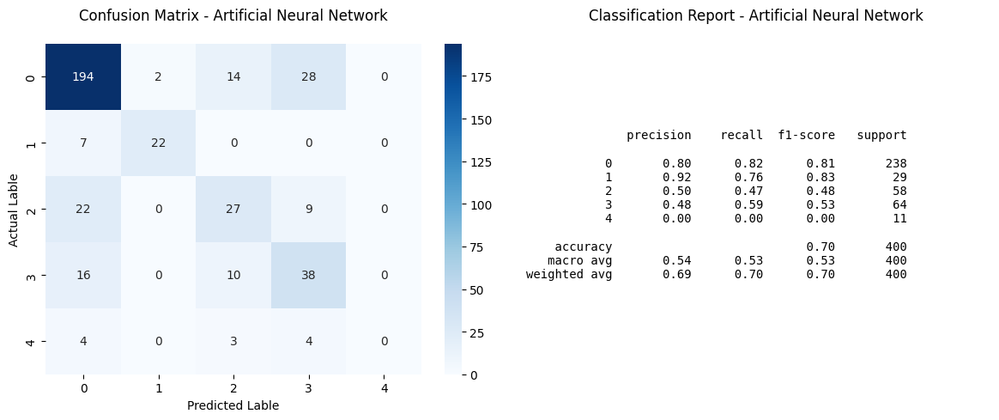

In [82]:
plot_model_performance(y_test_ann, ann_y_pred, model_name="Artificial Neural Network")

# csv

In [83]:
# Define a list to store model performance data
model_results = []

def evaluate_model(model_name, y_true, y_pred):
    report = classification_report(y_true, y_pred, output_dict=True)
    accuracy = accuracy_score(y_true, y_pred)
    
    # Extract weighted average precision, recall, and f1-score
    precision = report['weighted avg']['precision']
    recall = report['weighted avg']['recall']
    f1_score = report['weighted avg']['f1-score']
    
    # Append the results to the list
    model_results.append([model_name, precision, recall, f1_score, accuracy])

# Evaluate models

# Logistic Regression **
evaluate_model("Logistic Regression", y_test_lr, lr_y_pred)
evaluate_model("Tuned Logistic Regression", y_test_lr, y_pred_lr)

# Random Forest**
evaluate_model("Random Forest", y_test_rf, rf_y_pred)
evaluate_model("Tuned Random Forest", y_test_rf, y_pred_rf)

# XGBoost **
evaluate_model("XGBoost", y_test_xgb, xgb_y_pred)
evaluate_model("Tuned XGBoost", y_test_xgb, y_pred_xgb)


# LightGBM **
evaluate_model("LightGBM", y_test_lgb, lgb_y_pred)
evaluate_model("Tuned LightGBM", y_test_lgb, y_pred_lgb)

# Decision Tree
evaluate_model("Decision Tree", y_test_dt, dt_y_pred)
evaluate_model("Tuned Decision Tree", y_test_dt, y_pred_dt)

# SVM 
evaluate_model("SVM", y_test_svm, svm_y_pred)
evaluate_model("Tuned SVM", y_test_svm, y_pred_svm)

# K-Nearest Neighbors **
evaluate_model("K-Nearest Neighbors", y_test_knn, knn_y_pred)
evaluate_model("Tuned K-Nearest Neighbors", y_test_knn, y_pred_knn)

# Naive Bayes
evaluate_model("Naive Bayes", y_test_nb, nb_y_pred)

# Artificial Neural Network (ANN)
evaluate_model("Artificial Neural Network", y_test_ann, ann_y_pred)


# Convert results to DataFrame
results_df = pd.DataFrame(model_results, columns=["Model Name", "Precision", "Recall", "F1-Score", "Accuracy"])

# Save to CSV
results_df.to_csv("model_performance1.csv", index=False)

print("CSV file 'model_performance.csv' created successfully!")


CSV file 'model_performance.csv' created successfully!


C:\Users\aylin\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\metrics\_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
C:\Users\aylin\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\metrics\_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
C:\Users\aylin\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\metrics\_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, mo

In [84]:
# List to store model performance data
model_results = []

def evaluate_model(model_name, y_true, y_pred):
    report = classification_report(y_true, y_pred, output_dict=True)
    accuracy = accuracy_score(y_true, y_pred)
    
    # Extract weighted average precision, recall, and f1-score
    precision = report['weighted avg']['precision']
    recall = report['weighted avg']['recall']
    f1_score = report['weighted avg']['f1-score']
    
    model_results.append([model_name, precision, recall, f1_score, accuracy])

# Define your models with the associated suffix and whether they have a tuned version.
# The suffix corresponds to the variable naming pattern:
#   - Test data: y_test_<suffix>
#   - Basic predictions: <suffix>_y_pred
#   - Tuned predictions: y_pred_<suffix>
models = [
    {"name": "Logistic Regression",       "suffix": "lr",  "tuned": True},
    {"name": "Random Forest",             "suffix": "rf",  "tuned": True},
    {"name": "XGBoost",                   "suffix": "xgb", "tuned": True},
    {"name": "LightGBM",                  "suffix": "lgb", "tuned": True},
    {"name": "Decision Tree",             "suffix": "dt",  "tuned": True},
    {"name": "SVM",                       "suffix": "svm", "tuned": True},
    {"name": "K-Nearest Neighbors",       "suffix": "knn", "tuned": True},
    {"name": "Naive Bayes",               "suffix": "nb",  "tuned": False},
    {"name": "Artificial Neural Network", "suffix": "ann", "tuned": False},
]

# Loop over the models and evaluate each one
for model in models:
    suffix = model["suffix"]
    name = model["name"]
    
    # Build variable names for test and basic prediction data
    test_var_name = "y_test_" + suffix       # e.g., y_test_lr, y_test_rf, etc.
    basic_pred_var_name = suffix + "_y_pred"   # e.g., lr_y_pred, rf_y_pred, etc.
    
    # Retrieve the actual variables from the global namespace
    y_test_var = globals()[test_var_name]
    basic_pred = globals()[basic_pred_var_name]
    
    # Evaluate the basic model
    evaluate_model(name, y_test_var, basic_pred)
    
    # If a tuned version exists, evaluate it as well.
    if model["tuned"]:
        tuned_pred_var_name = "y_pred_" + suffix  # e.g., y_pred_lr, y_pred_rf, etc.
        tuned_pred = globals()[tuned_pred_var_name]
        evaluate_model("Tuned " + name, y_test_var, tuned_pred)

# Convert the results into a DataFrame and save to CSV
results_df = pd.DataFrame(model_results, columns=["Model Name", "Precision", "Recall", "F1-Score", "Accuracy"])
results_df.to_csv("model_performance_optimized1.csv", index=False)

print("CSV file 'model_performance.csv' created successfully!")


CSV file 'model_performance.csv' created successfully!


C:\Users\aylin\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\metrics\_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
C:\Users\aylin\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\metrics\_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
C:\Users\aylin\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\metrics\_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, mo

# ROC curve

In [85]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc, RocCurveDisplay
from sklearn.preprocessing import label_binarize
from itertools import cycle
import numpy as np

def plot_multiclass_roc_curves(models, figsize=(15, 12)):
    """
    Plot ROC curves for all models (multiclass - 5 classes)
    """
    # Setup plot
    plt.figure(figsize=figsize)
    
    # Colors for different models
    colors = cycle(['blue', 'red', 'green', 'orange', 'purple', 'brown', 'pink', 'gray', 'olive', 'cyan'])
    
    # Define class names for your 5 classes
    class_names = ['Class 0', 'Class 1', 'Class 2', 'Class 3', 'Class 4']
    n_classes = 5
    
    # Line styles for basic vs tuned models
    line_styles = {'basic': '-', 'tuned': '--'}
    
    for i, model in enumerate(models):
        suffix = model["suffix"]
        name = model["name"]
        color = next(colors)
        
        # Get test data
        y_test = globals()[f"y_test_{suffix}"]
        
        # Binarize the test labels
        y_test_bin = label_binarize(y_test, classes=[0, 1, 2, 3, 4])
        
        # Basic model ROC
        basic_proba_name = f"{suffix}_y_pred_proba"
        if basic_proba_name in globals():
            y_pred_proba = globals()[basic_proba_name]
            
            # Compute ROC curve and ROC area for each class
            fpr = dict()
            tpr = dict()
            roc_auc = dict()
            
            for class_idx in range(n_classes):
                fpr[class_idx], tpr[class_idx], _ = roc_curve(y_test_bin[:, class_idx], y_pred_proba[:, class_idx])
                roc_auc[class_idx] = auc(fpr[class_idx], tpr[class_idx])
            
            # Plot each class
            for class_idx in range(n_classes):
                plt.plot(fpr[class_idx], tpr[class_idx], linestyle=line_styles['basic'],
                        color=color, alpha=0.7, linewidth=1,
                        label=f'{name} {class_names[class_idx]} (AUC = {roc_auc[class_idx]:.3f})')
        
        # Tuned model ROC
        if model["tuned"]:
            tuned_proba_name = f"y_pred_{suffix}_proba"
            if tuned_proba_name in globals():
                y_pred_proba = globals()[tuned_proba_name]
                
                # Compute ROC curve and ROC area for each class
                fpr = dict()
                tpr = dict()
                roc_auc = dict()
                
                for class_idx in range(n_classes):
                    fpr[class_idx], tpr[class_idx], _ = roc_curve(y_test_bin[:, class_idx], y_pred_proba[:, class_idx])
                    roc_auc[class_idx] = auc(fpr[class_idx], tpr[class_idx])
                
                # Plot each class with dashed lines for tuned models
                for class_idx in range(n_classes):
                    plt.plot(fpr[class_idx], tpr[class_idx], linestyle=line_styles['tuned'],
                            color=color, alpha=0.7, linewidth=1,
                            label=f'Tuned {name} {class_names[class_idx]} (AUC = {roc_auc[class_idx]:.3f})')
    
    # Plot random classifier line
    plt.plot([0, 1], [0, 1], 'k--', linewidth=2, label='Random Classifier')
    
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('ROC Curves for All Models (Multiclass - One-vs-Rest)')
    plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=8)
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

# Alternative: Micro-average ROC curve (simpler view)
def plot_micro_average_roc(models, figsize=(12, 8)):
    """
    Plot micro-average ROC curves for easier comparison
    """
    plt.figure(figsize=figsize)
    
    colors = cycle(['blue', 'red', 'green', 'orange', 'purple', 'brown', 'pink', 'gray', 'olive', 'cyan'])
    
    for i, model in enumerate(models):
        suffix = model["suffix"]
        name = model["name"]
        color = next(colors)
        
        y_test = globals()[f"y_test_{suffix}"]
        y_test_bin = label_binarize(y_test, classes=[0, 1, 2, 3, 4])
        
        # Basic model
        basic_proba_name = f"{suffix}_y_pred_proba"
        if basic_proba_name in globals():
            y_pred_proba = globals()[basic_proba_name]
            
            # Micro-average ROC
            fpr, tpr, _ = roc_curve(y_test_bin.ravel(), y_pred_proba.ravel())
            roc_auc = auc(fpr, tpr)
            
            plt.plot(fpr, tpr, color=color, linewidth=1.5,
                    label=f'{name} (AUC = {roc_auc:.3f})')
        
        # Tuned model
        if model["tuned"]:
            tuned_proba_name = f"y_pred_{suffix}_proba"
            if tuned_proba_name in globals():
                y_pred_proba = globals()[tuned_proba_name]
                
                # Micro-average ROC
                fpr, tpr, _ = roc_curve(y_test_bin.ravel(), y_pred_proba.ravel())
                roc_auc = auc(fpr, tpr)
                
                plt.plot(fpr, tpr, color=color, linestyle='--', linewidth=2,
                        label=f'Tuned {name} (AUC = {roc_auc:.3f})')
    
    plt.plot([0, 1], [0, 1], 'k--', linewidth=2, label='Random Classifier')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('Micro-average ROC Curves for All Models')
    plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

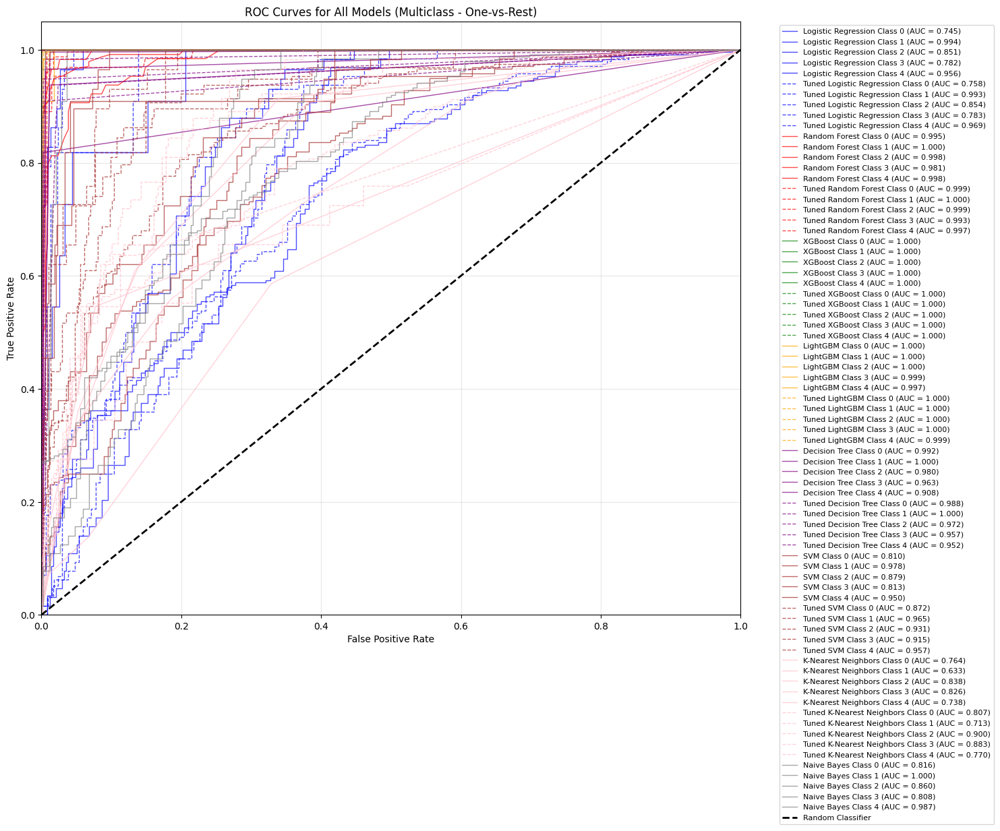

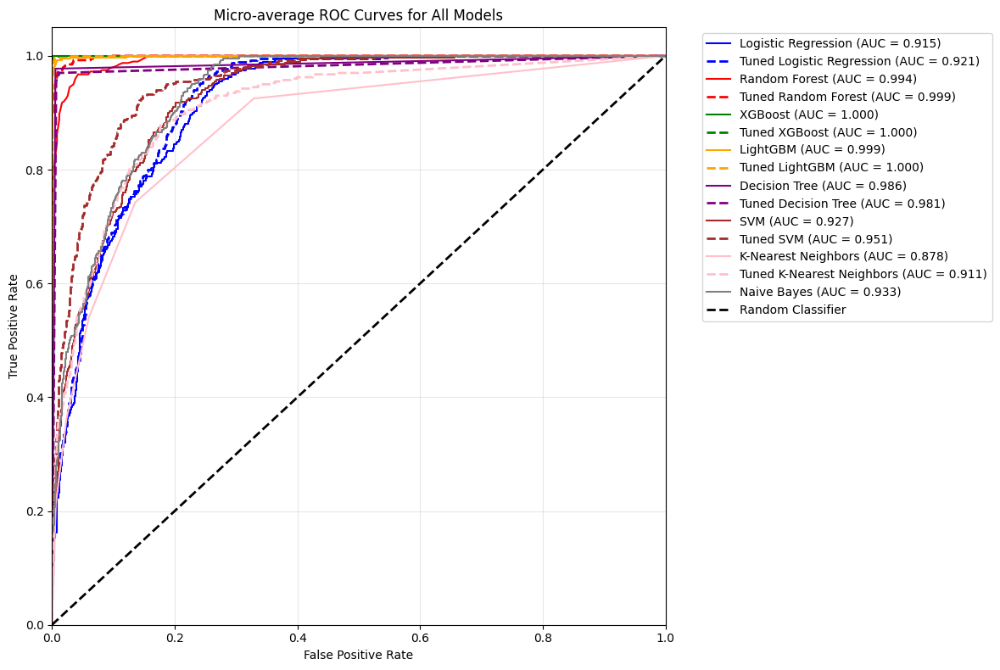

In [86]:
# Detailed view with all classes
plot_multiclass_roc_curves(models)

# Simplified micro-average view
plot_micro_average_roc(models)